# The Midnight Queue
### Ranking suspicious transactions at scale · 23I-2581 · DS-B

**Design and Analysis of Algorithms — Assignment 2**

| Parameter | Value |
|---|---|
| Roll (display) | 23I-2581 |
| Seed | 232581 |
| Section | DS-B |
| Shift capacity | $K = 25 + (232581 \bmod 226) = 52$ |
| Sizes | 1,000 · 10,000 · 100,000 · 284,807 |
| Dataset | Kaggle `mlg-ulb/creditcardfraud` (`creditcard.csv`, not redistributed) |

This notebook is a **walkthrough**, not the benchmark harness.  It loads the
real file, demonstrates the risk score, the four-field comparator and the
custom contenders on small samples, then reads the frozen five-run medians in
`outputs/raw/` and `results.csv`.  The complete tournament takes tens of
minutes and is reproduced with the commands in `README.md`; rerunning it here
would only duplicate measurements.

**What is live in this notebook:** the dataset checksum/profile, a 1,000-record
sorting check, a 10,000-record Top-K check, and the fraud-capture table.
**What is read from disk:** every tournament, Top-K, live-feed and memory
number.  Those are the numbers printed in the report.

> **AI-use disclosure.** The original project records assistance from OpenCode
> with DeepSeek V4.1 Flash for implementation, tests, experiment orchestration,
> analysis and drafting. OpenAI Codex helped revise the visualisation code,
> notebook presentation, compliance checks and editable LaTeX report in this
> revision, then hardened quicksort, corrected the C6 model and timing scopes,
> and reran affected experiments. Historical observations are archived;
> over-limit C5 insertion runs remain excluded under the 300-second rule.
> The student must verify
> the submission and be able to explain and modify the algorithms in the viva.

## 0. Setup and personal parameters

`src/` is added to `sys.path` so the notebook runs from a plain checkout
without installation.  The `CONFIG` object validates that the roll digits,
seed and $K$ are mutually consistent.

In [1]:
from pathlib import Path
import json
import sys
import time

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src" / "midnight_queue").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the midnight_queue project folder.")
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, HTML, display

from midnight_queue.config import CONFIG
from midnight_queue.data import dataset_profile, load_dataset, sample_records
from midnight_queue.records import Counters, TriageOrder, triage_key
from midnight_queue.sorting import SORT_ALGORITHMS
from midnight_queue.topk import topk_buffer, topk_heap

print(f"roll={CONFIG.roll_display}  seed={CONFIG.seed}  section={CONFIG.section}")
print(f"K={CONFIG.k}  sizes={CONFIG.sizes}")
print(f"project root: {ROOT}")

roll=23I-2581  seed=232581  section=DS-B
K=52  sizes=(1000, 10000, 100000, 284807)
project root: C:\Users\hp\Desktop\University\3. Algo\2. Assignments\ASM - 2\midnight_queue


In [2]:
from html import escape
from midnight_queue.visuals import main as build_figures

# Rebuild only visual assets from the recorded CSVs, never the benchmarks.
build_figures()
figure_dir = ROOT / "outputs" / "figures"
captions = json.loads((figure_dir / "captions.json").read_text(encoding="utf-8"))

def show_figure(name):
    """Embed a sharp PNG and its evidence-backed caption in this notebook."""
    display(Image(filename=str(figure_dir / name), width=1100))
    display(HTML('<p style="font:13px/1.6 sans-serif;color:#5b7080;'
                 'border-left:3px solid #008c95;padding:8px 14px;margin:0 0 24px">'
                 + escape(captions[name]) + '</p>'))

def style_table(frame):
    """Use one accessible table style without changing the underlying numbers."""
    return (frame.style.format(precision=4, na_rep="—")
            .set_table_styles([
                {"selector":"th", "props":[("background-color","#18364b"),
                  ("color","white"),("padding","10px 12px"),("text-align","left")]},
                {"selector":"td", "props":[("padding","9px 12px"),
                  ("border-bottom","1px solid #e3eaf0")]},
                {"selector":"tr:nth-child(even)", "props":[("background-color","#f4f8fb")]},
                {"selector":"table", "props":[("font-family","sans-serif"),
                  ("font-size","13px"),("border-collapse","collapse")]},
            ]))

Exported 15 figures as PNG, PDF and SVG to C:\Users\hp\Desktop\University\3. Algo\2. Assignments\ASM - 2\midnight_queue\outputs\figures


In [3]:
display(HTML("""
<div style="background:#18364b;color:white;padding:28px 32px;border-radius:12px;
            font-family:sans-serif;margin:12px 0 24px">
  <div style="color:#9dd6d5;font-size:12px;letter-spacing:2px">ALGORITHMS · EVIDENCE · DECISIONS</div>
  <div style="font-size:27px;font-weight:700;margin:10px 0 16px">The cost of finding the right queue</div>
  <div style="display:flex;gap:45px;flex-wrap:wrap">
    <div><b style="font-size:24px">284,807</b><br><span style="color:#cbd9e2">transactions</span></div>
    <div><b style="font-size:24px">52</b><br><span style="color:#cbd9e2">cases per shift</span></div>
    <div><b style="font-size:24px">2,068</b><br><span style="color:#cbd9e2">cases to capture 50% of frauds</span></div>
  </div>
</div>"""))

## A. Know your data

Risk is the sum of 28 squared population z-scores over `V1…V28`:

$$ r_i = \sum_{j=1}^{28} z_{ij}^2, \qquad
   b_i = \min(9,\max(0,\lfloor \log_2 r_i \rfloor)). $$

The score never reads `Amount`, `Time`, `txn_id` or `Class`.  Loading the full
file validates the schema, finite values, binary labels and ascending `Time`,
then computes the score for every row.  It takes roughly 10–20 seconds.

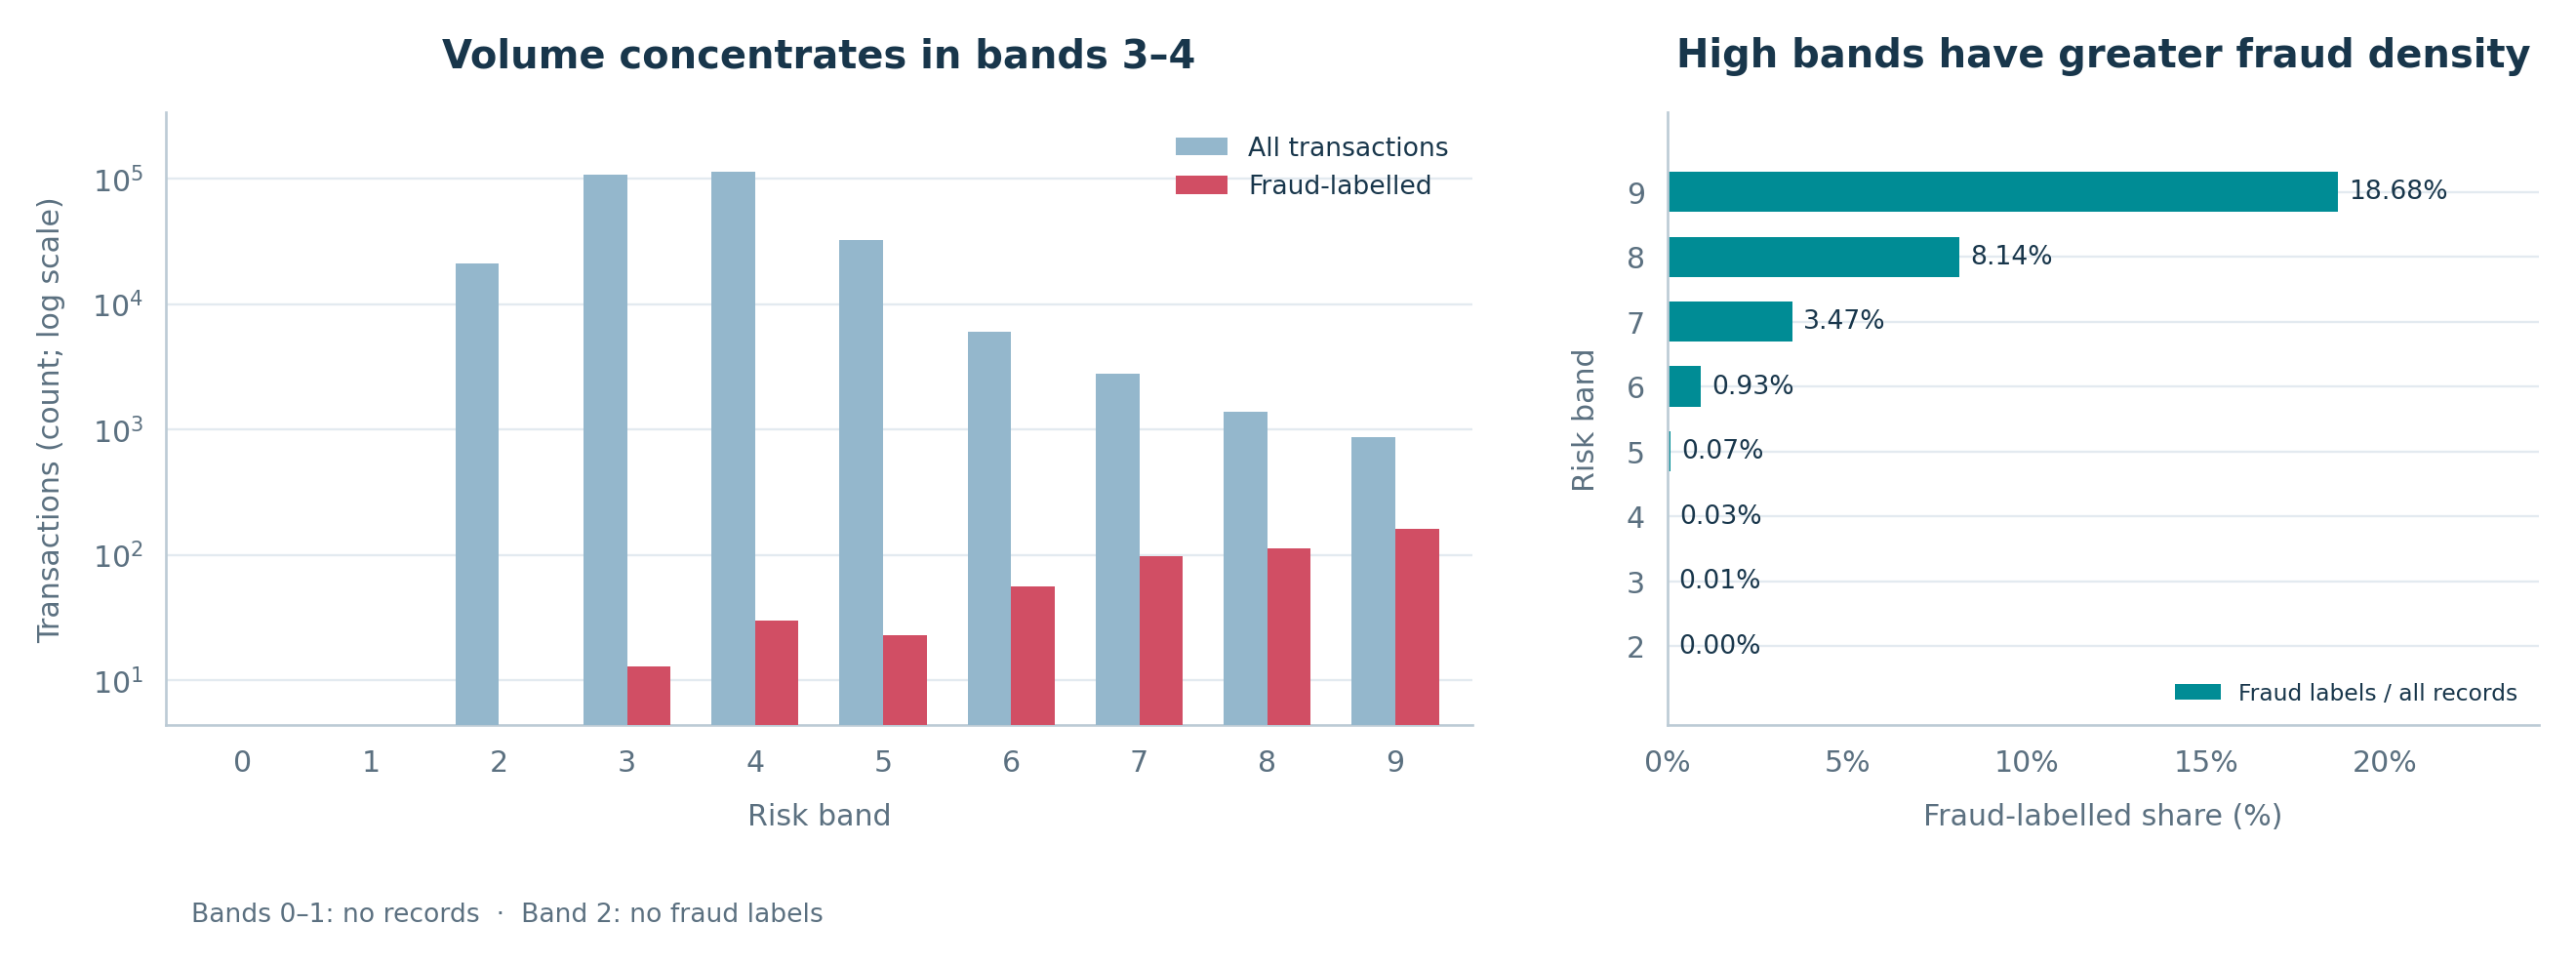

In [4]:
show_figure("07_band_distribution.png")

In [5]:
data_path = ROOT / "data" / "creditcard.csv"
if not data_path.exists():
    raise FileNotFoundError(
        "Place creditcard.csv at data/creditcard.csv (see README.md)."
    )

started = time.perf_counter()
dataset = load_dataset(data_path)
profile = dataset_profile(dataset)
print(f"loaded {dataset.n:,} rows in {time.perf_counter() - started:.1f}s")
print(f"sha256 = {dataset.sha256}")
print(f"frauds = {dataset.fraud_count}")
assert dataset.n == 284_807 and dataset.fraud_count == 492
assert dataset.sha256 == "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"

loaded 284,807 rows in 5.5s
sha256 = 76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89
frauds = 492


In [6]:
def band_count(mapping, band):
    return mapping.get(band, mapping.get(str(band), 0))


band_rows = []
for band in range(10):
    band_rows.append(
        {
            "band": band,
            "transactions": band_count(profile["band_counts"], band),
            "frauds": band_count(profile["fraud_by_band"], band),
        }
    )
band_table = pd.DataFrame(band_rows)
band_table["share of row count"] = (
    band_table["transactions"] / dataset.n
).map(lambda v: f"{v:.2%}")
band_table

,band,transactions,frauds,share of row count
0,0,0,0,0.00%
1,1,0,0,0.00%
2,2,21156,0,7.43%
3,3,107410,13,37.71%
4,4,113116,30,39.72%
5,5,32084,23,11.27%
6,6,6006,56,2.11%
7,7,2797,97,0.98%
8,8,1376,112,0.48%
9,9,862,161,0.30%


In [7]:
print(f"distinct Amount values: {profile['distinct_amounts']:,}")
print(f"top-10 Amount share:    {profile['top10_amount_share']:.3%}")
print("top Amount values:")
for item in profile["top10_amounts"][:5]:
    print(f"  {item['amount']:>8.2f}  x{item['count']:,}")

distinct Amount values: 32,767
top-10 Amount share:    16.291%
top Amount values:
      1.00  x13,688
      1.98  x6,044
      0.89  x4,872
      9.99  x4,747
     15.00  x3,280


**Reading.**  Bands 0–1 are empty in this file; the top band (9) has only 862
transactions but 161 frauds.  Fraud is concentrated at high risk, yet the raw
file is sorted by `Time`, which is unrelated to the triage order.  That is why
a full sort is needed before taking the first $K$.

The four-field key is **band descending, Amount descending, Time ascending,
txn_id ascending**.  `Class` is evaluation-only.

## Demo: build a 10,000-record C1 input and rank it

`sample_records` uses `numpy.random.default_rng(232581)`, samples without
replacement, then restores `(Time, txn_id)` order.  The result is condition C1
(arrival order) for that size.  The same records are shared by all conditions
in the real harness; C2 shuffles them and C3 ranks them, etc.

In [8]:
records = sample_records(dataset.records, 10_000, CONFIG.seed)
print(f"sampled {len(records):,} records; first/last Time = "
      f"{records[0].time:.0f} / {records[-1].time:.0f}")
print(f"first five txn_ids: {[t.txn_id for t in records[:5]]}")

reference = sorted(records, key=triage_key)  # reference only, not a contender
preview = pd.DataFrame(
    [
        {
            "rank": i + 1,
            "txn_id": t.txn_id,
            "band": t.band,
            "Amount": round(t.amount, 2),
            "Time": round(t.time, 1),
            "risk": round(t.risk, 4),
            "Class": t.label,
        }
        for i, t in enumerate(reference[:10])
    ]
)
style_table(preview)

sampled 10,000 records; first/last Time = 12 / 172768
first five txn_ids: [16, 40, 84, 89, 109]


,rank,txn_id,band,Amount,Time,risk,Class
0,1,227922,9,10000.0000,145283.0000,4691.1546,0
1,2,67725,9,5657.5400,52672.0000,1118.5479,0
2,3,117384,9,3759.3900,74657.0000,1184.0597,0
3,4,244699,9,1565.1200,152452.0000,538.6482,0
4,5,78383,9,1502.3600,57502.0000,675.8245,0
5,6,20261,9,870.0000,30907.0000,918.1529,0
6,7,153852,9,779.8600,100384.0000,1695.6409,0
7,8,184330,9,570.0000,126199.0000,778.0161,0
8,9,79297,9,390.6500,57957.0000,3314.6539,0
9,10,158023,9,360.0000,110803.0000,719.3539,0


## B. Correctness and cost of the custom contenders

All five full-sort contenders implement the same interface.  A comparison is
one call to `TriageOrder.cmp`; a move is one record assignment (a swap counts
as three).  No built-in or NumPy sort appears inside any contender.

The check below uses **1,000 records**, not 10,000, so that quadratic
contenders finish quickly.  It verifies exact sequence equality and reports an
illustrative single run.  The report uses five-run medians from the frozen
harness; these numbers are not substituted for them.

In [9]:
small = records[:1_000]
expected = sorted(small, key=triage_key)  # reference only

rows = []
for name, algorithm in SORT_ALGORITHMS.items():
    counters = Counters()
    order = TriageOrder("triage", counters)
    work = list(small)  # fresh input copy, outside the timer
    start = time.perf_counter()
    output = algorithm(work, order, counters)
    elapsed = time.perf_counter() - start
    rows.append(
        {
            "contender": name,
            "correct": output == expected,
            "elapsed_s": round(elapsed, 4),
            "comparisons": counters.comparisons,
            "moves": counters.moves,
        }
    )
assert all(row["correct"] for row in rows), "A sorting contender disagrees with the reference"
style_table(pd.DataFrame(rows).sort_values("elapsed_s"))

,contender,correct,elapsed_s,comparisons,moves
2,Naive Quick Sort,True,0.0046,11007,13797
1,Merge Sort,True,0.0067,8593,19952
4,Heap Sort,True,0.0069,16783,27291
3,Hardened Quick Sort,True,0.0083,11496,27669
0,Insertion Sort,True,0.0973,226328,226336


## C. The measured tournament (read from disk)

Every cell is the median of five completed runs.  `DNF` means a genuine
300-second timeout; it is never given a time or a median.  The table shows the
report's representative slice at $n=10{,}000$.

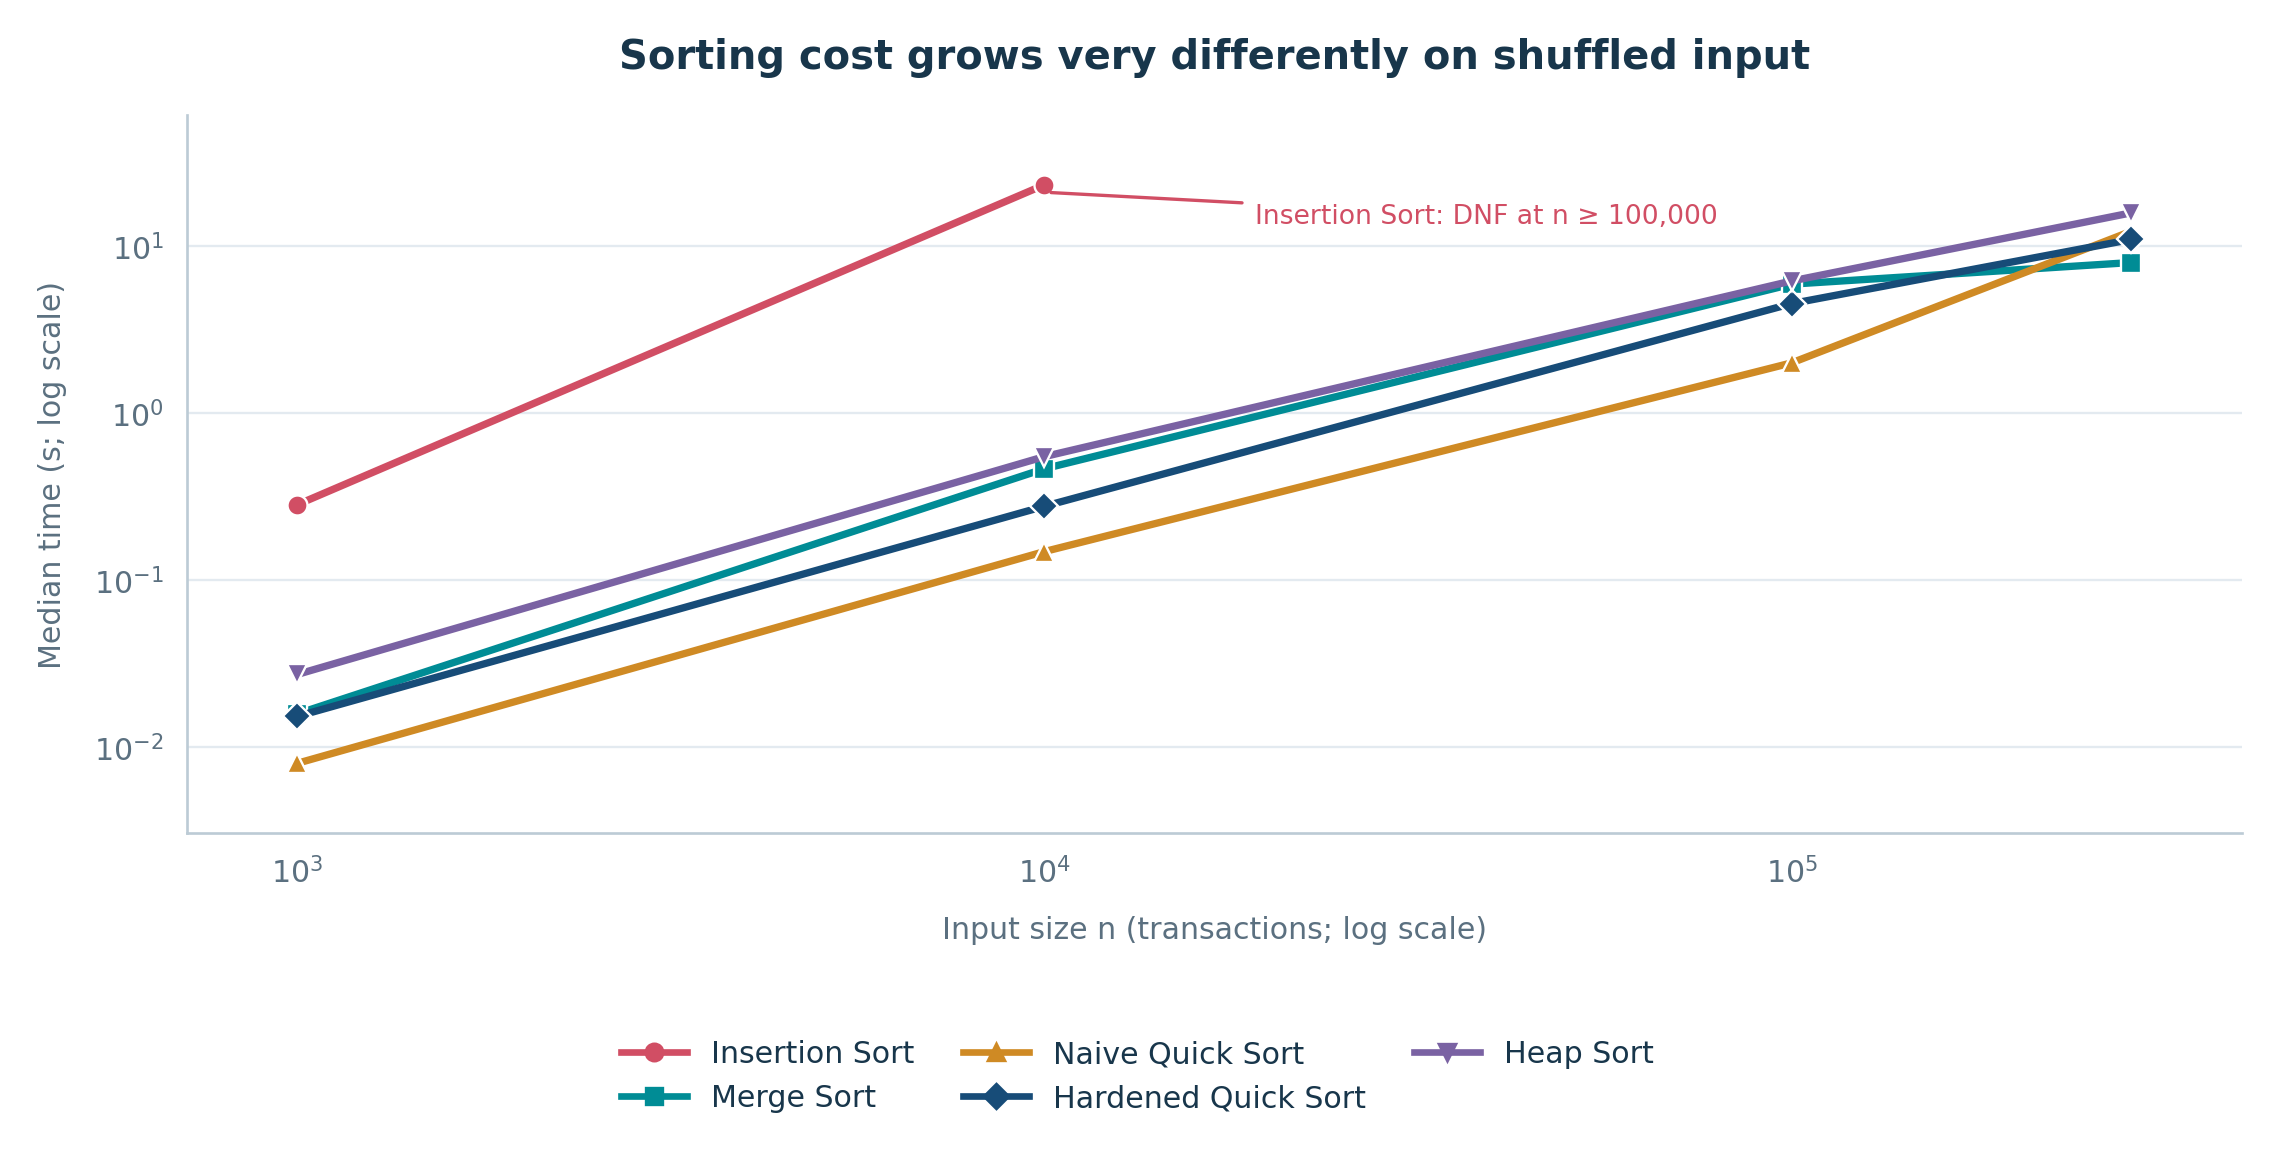

In [10]:
show_figure("01_time_vs_n_C2.png")

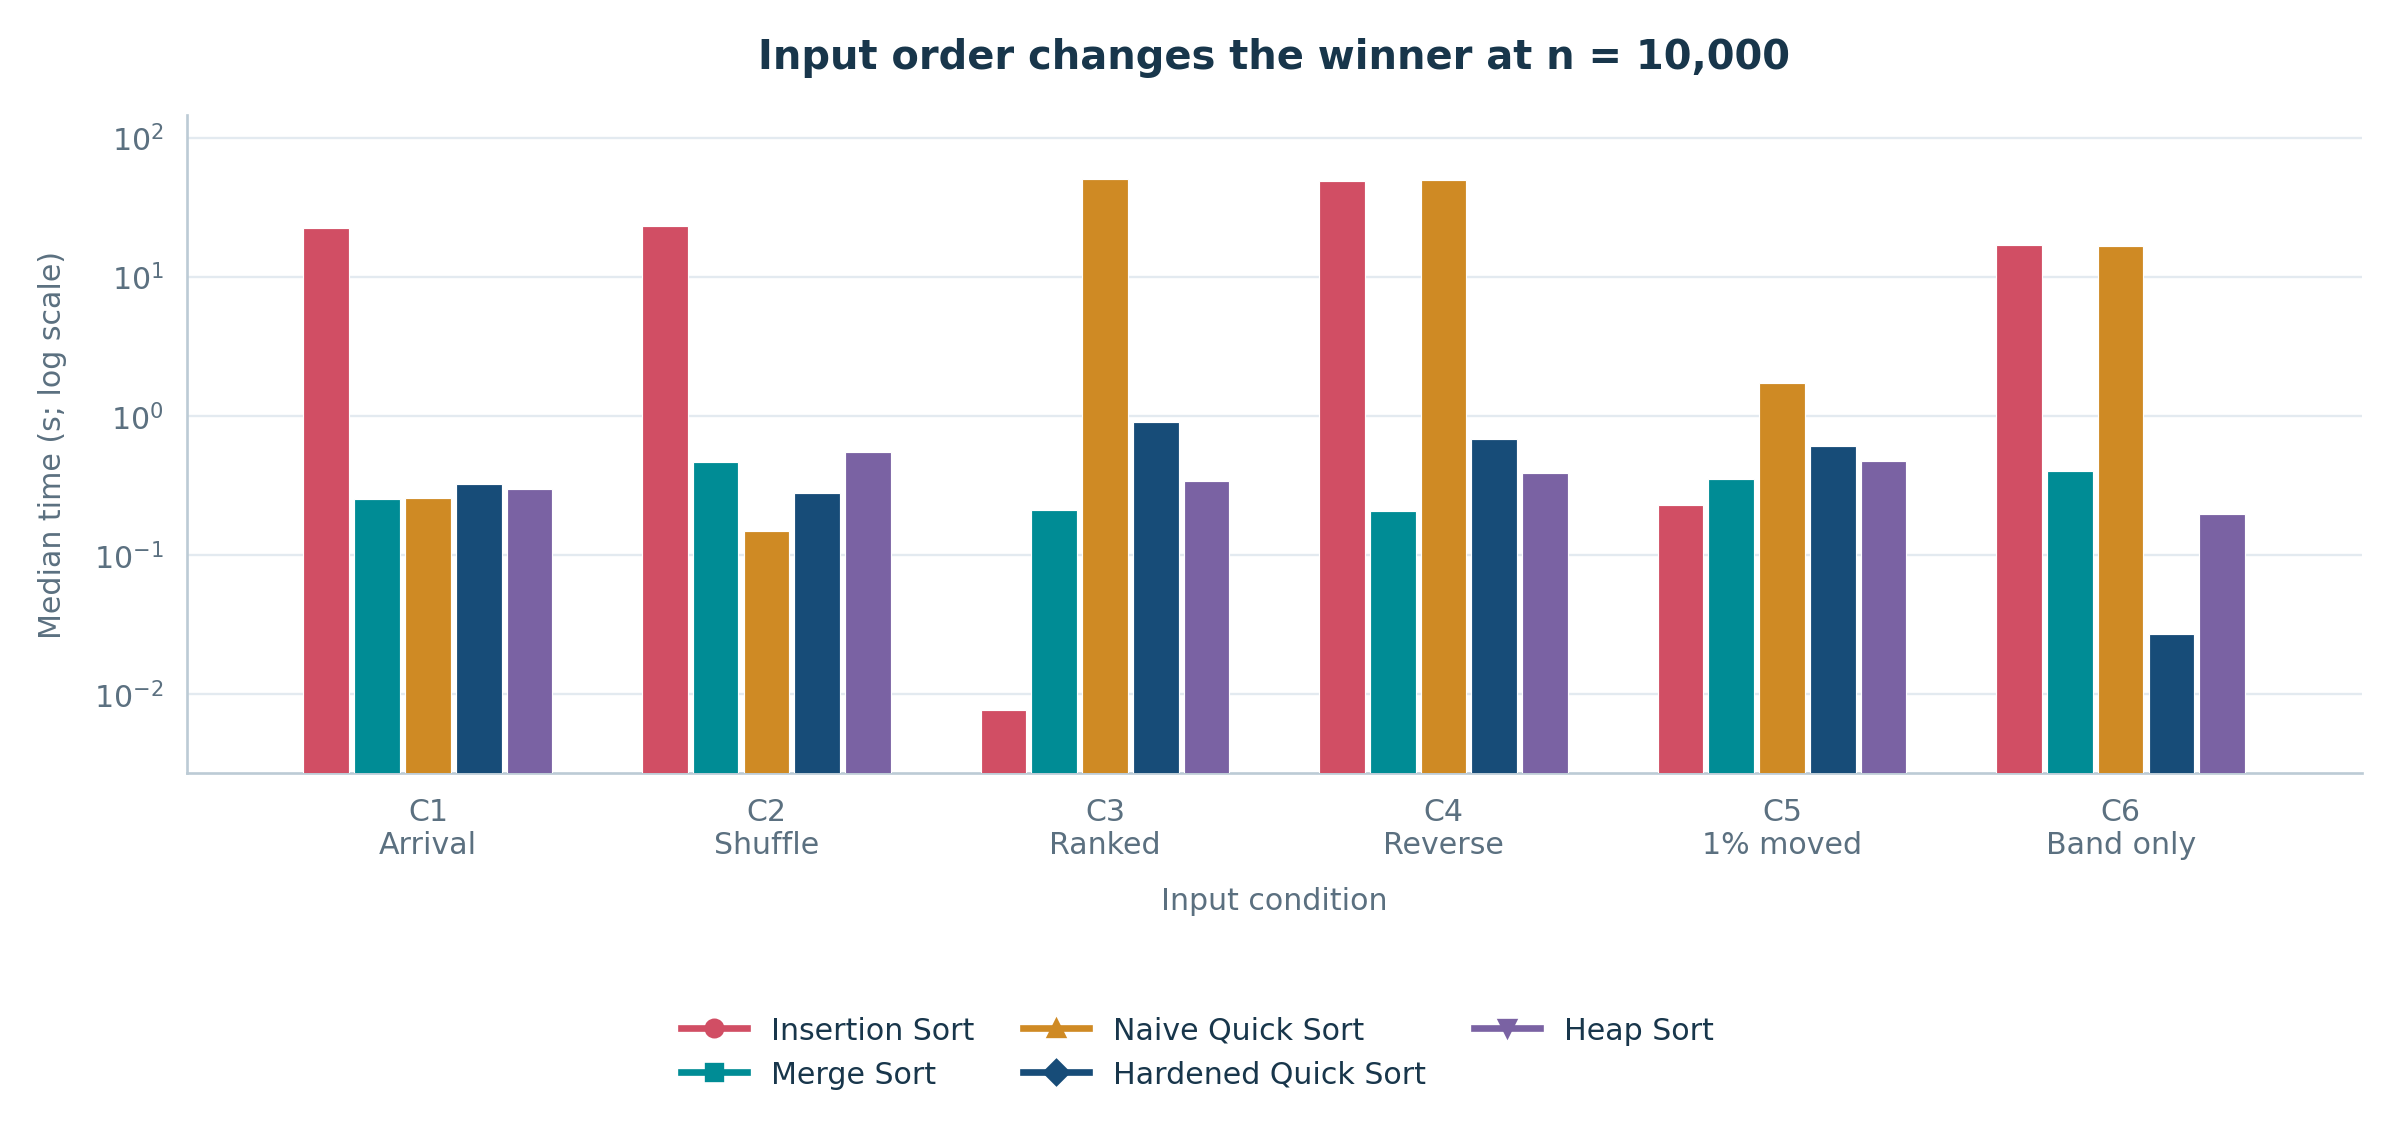

In [11]:
show_figure("02_time_by_condition_n10000.png")

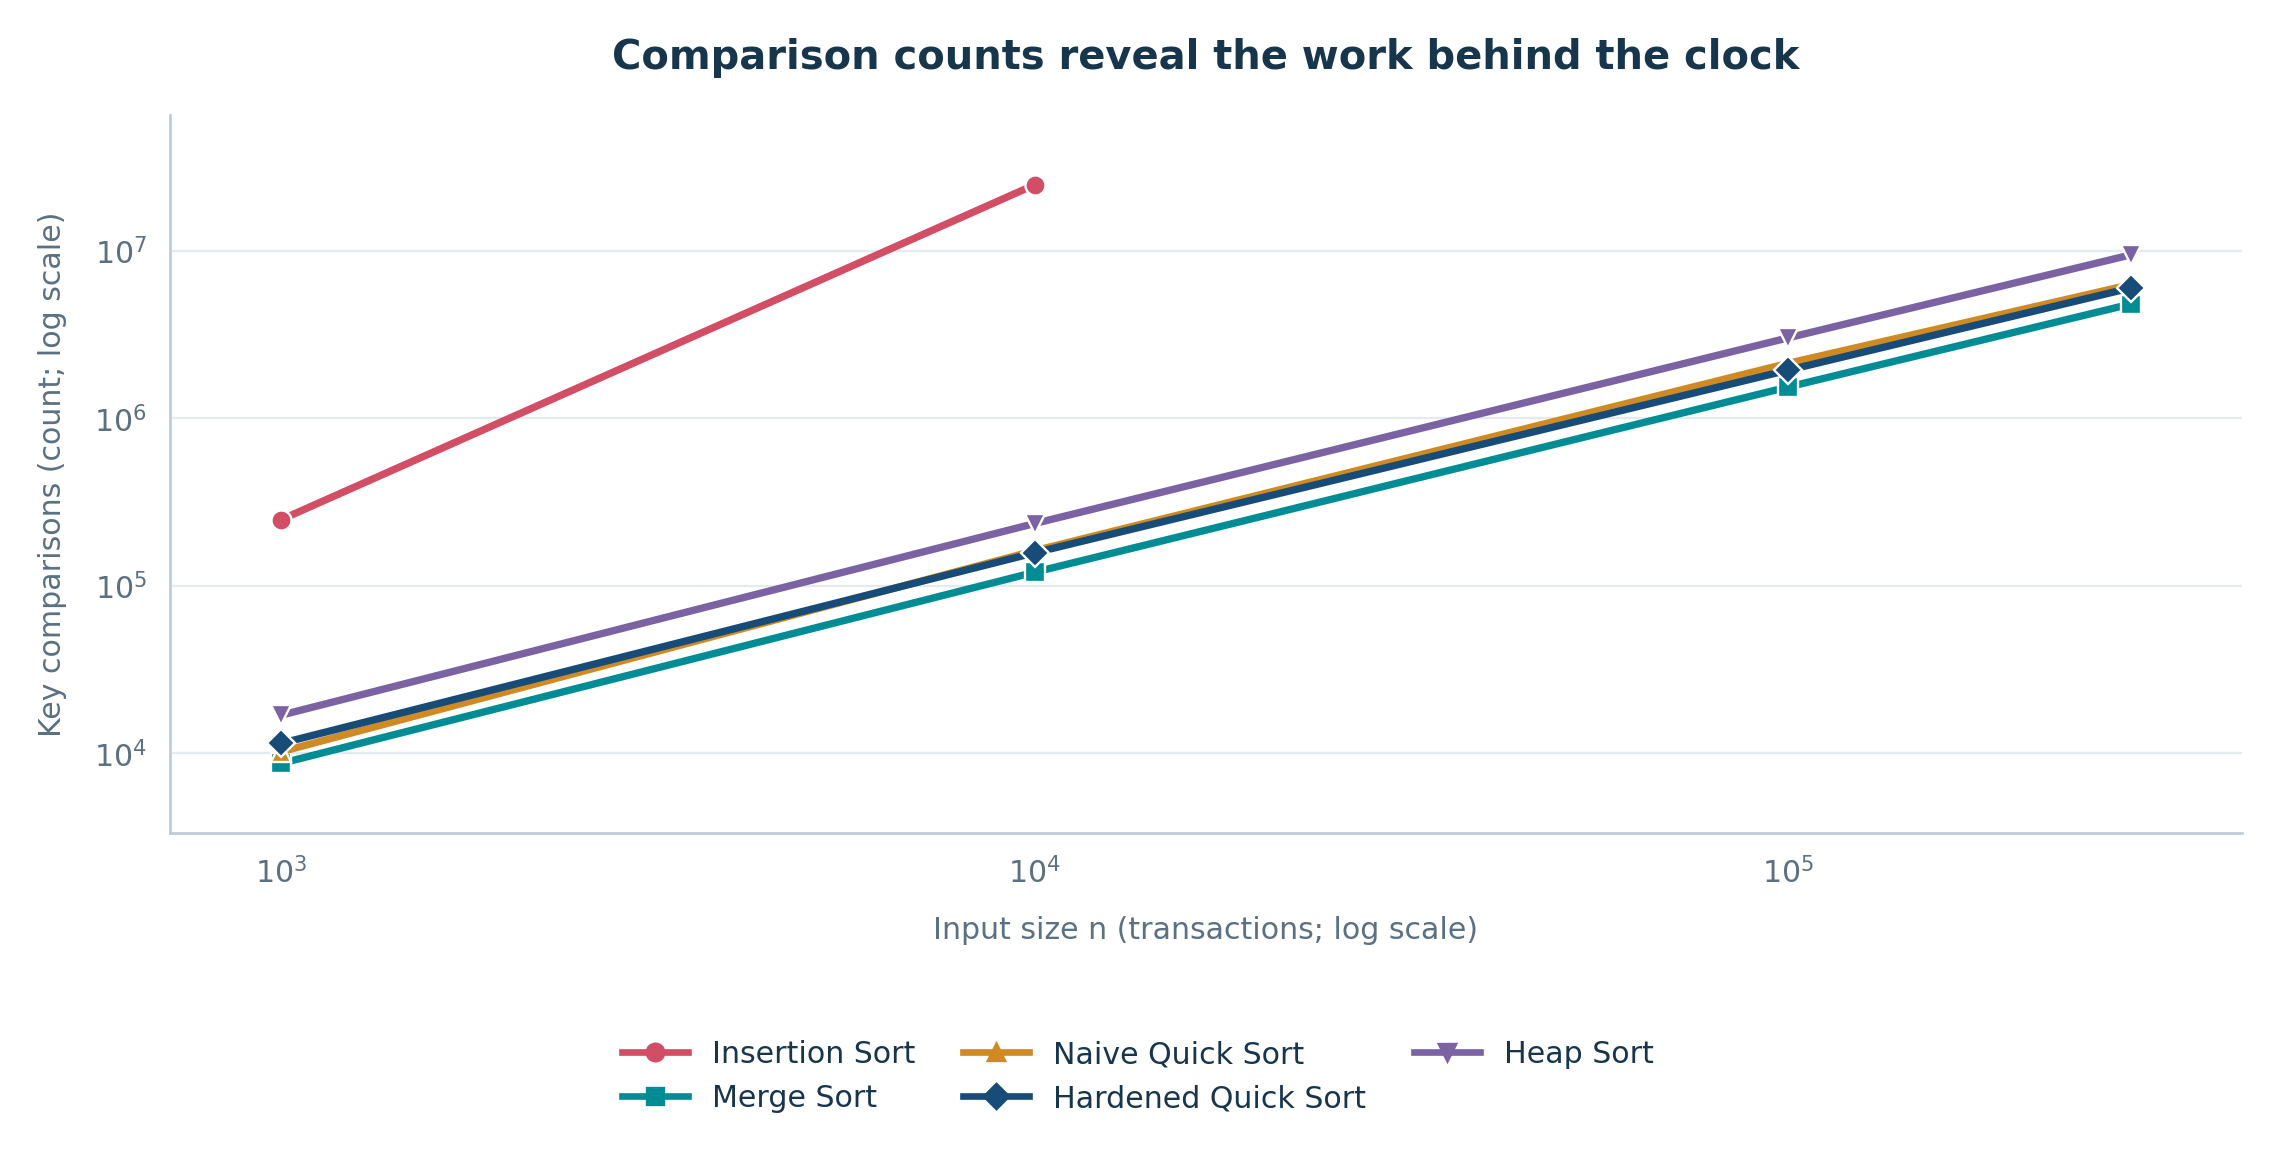

In [12]:
show_figure("03_comparisons_vs_n_C2.png")

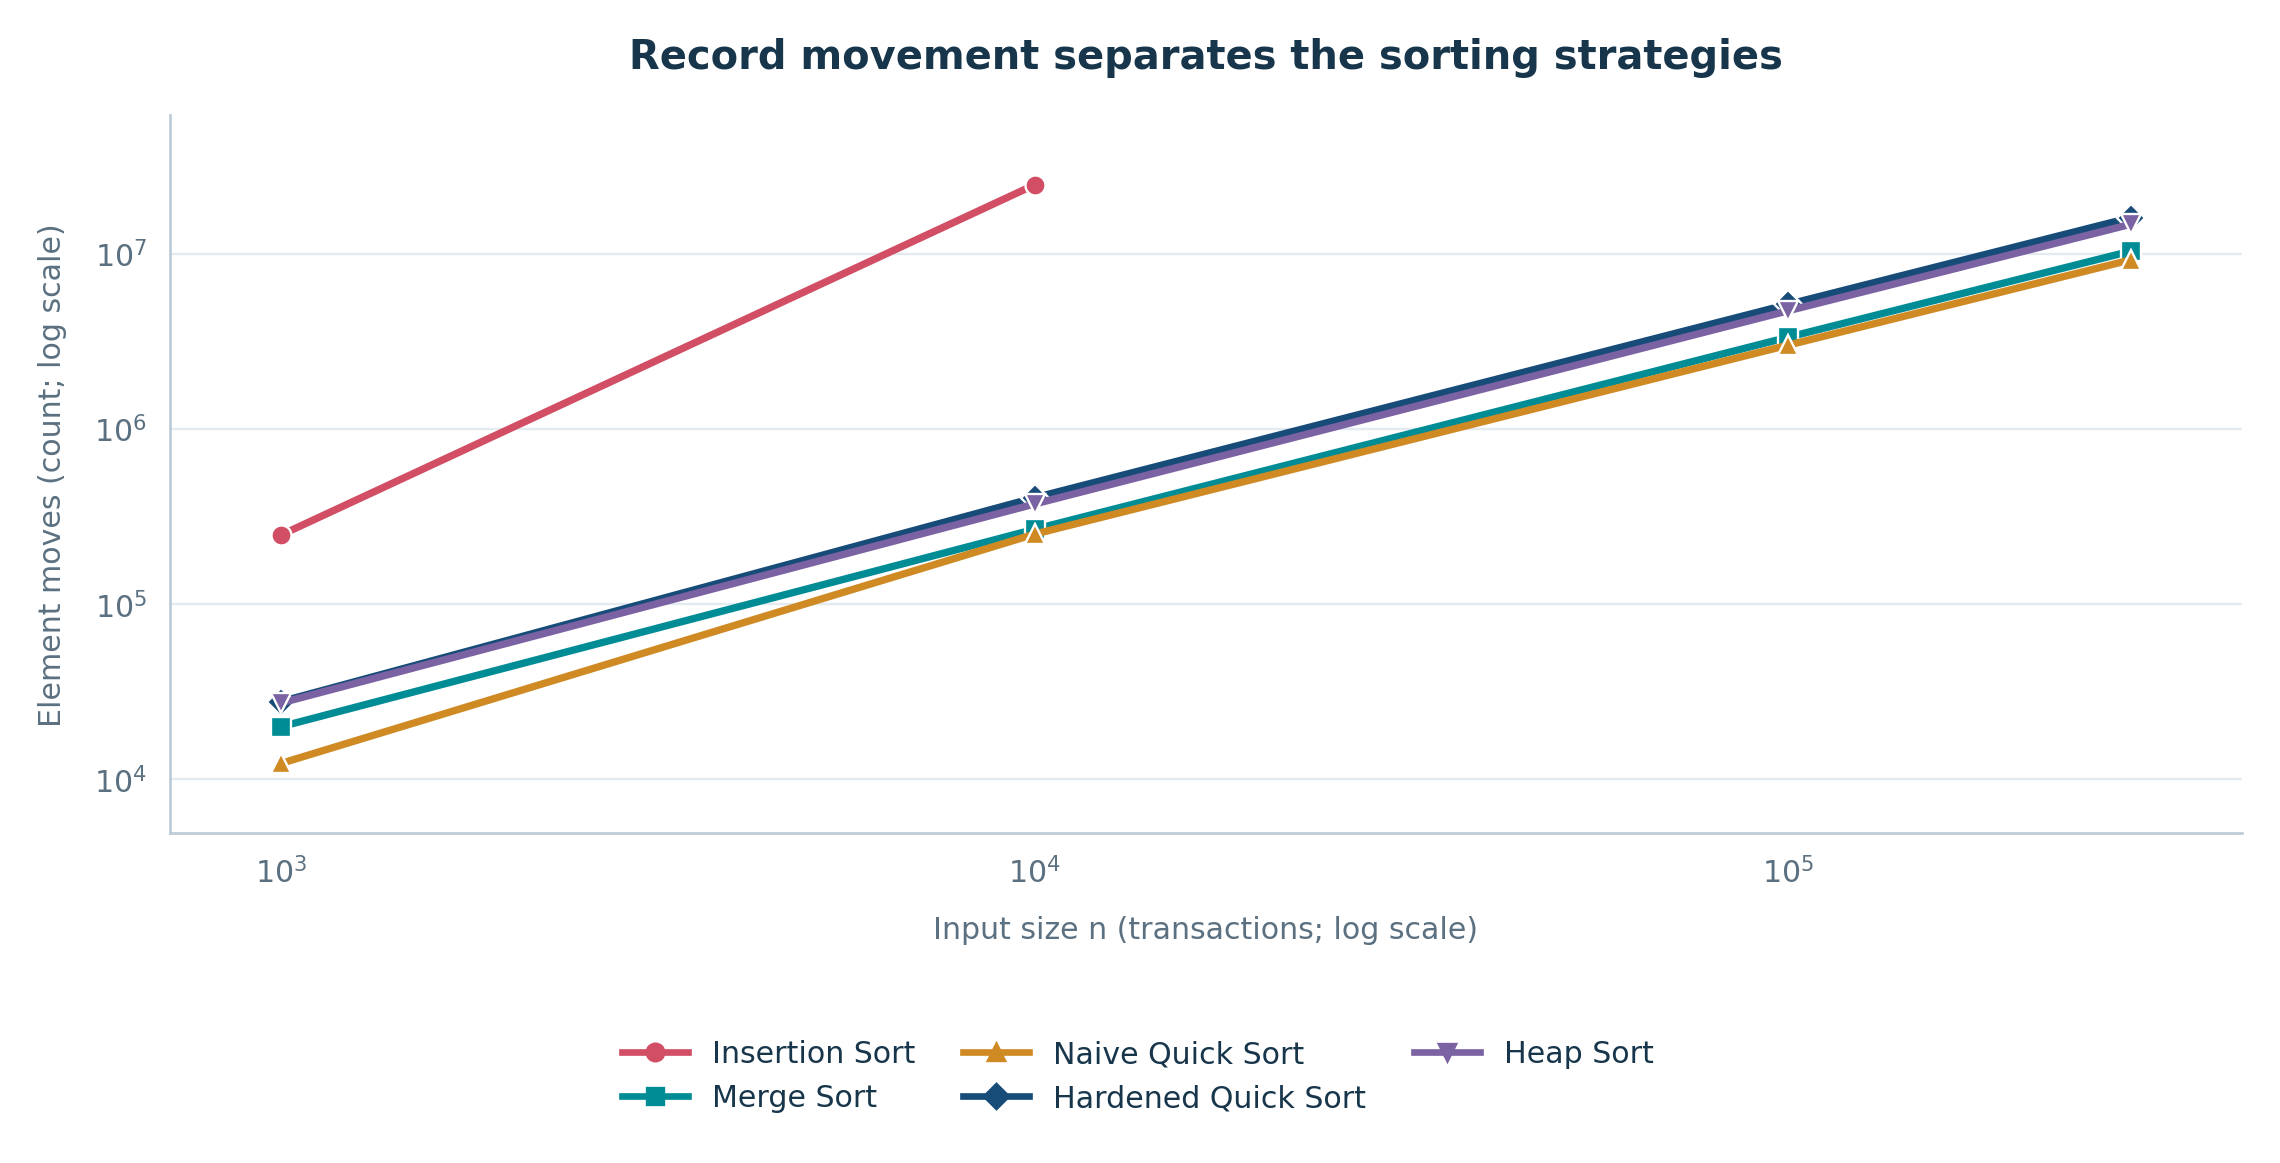

In [13]:
show_figure("04_moves_vs_n_C2.png")

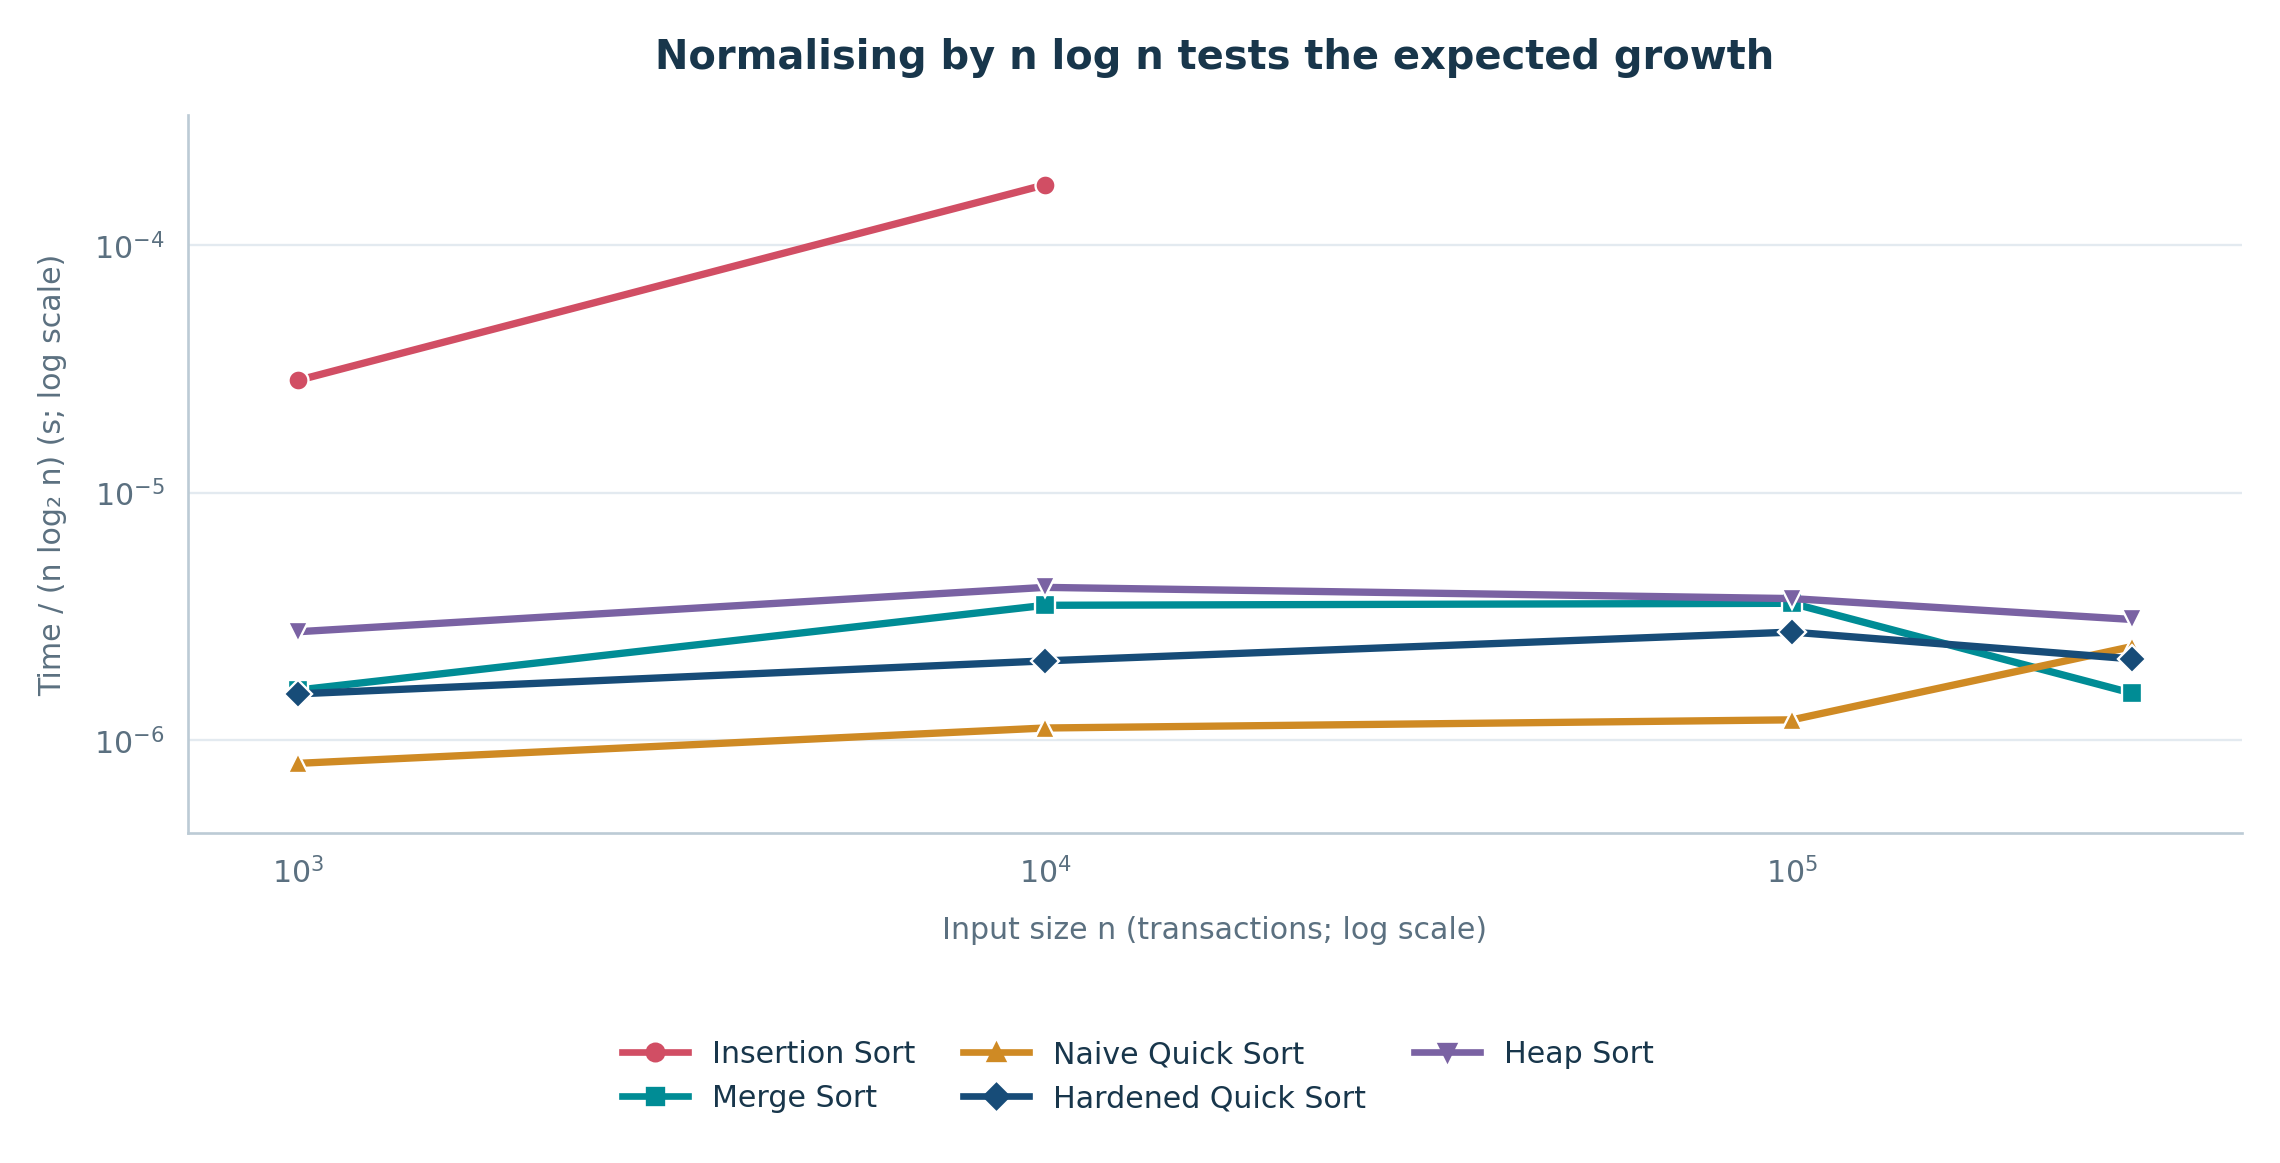

In [14]:
show_figure("05_time_nlogn_vs_n_C2.png")

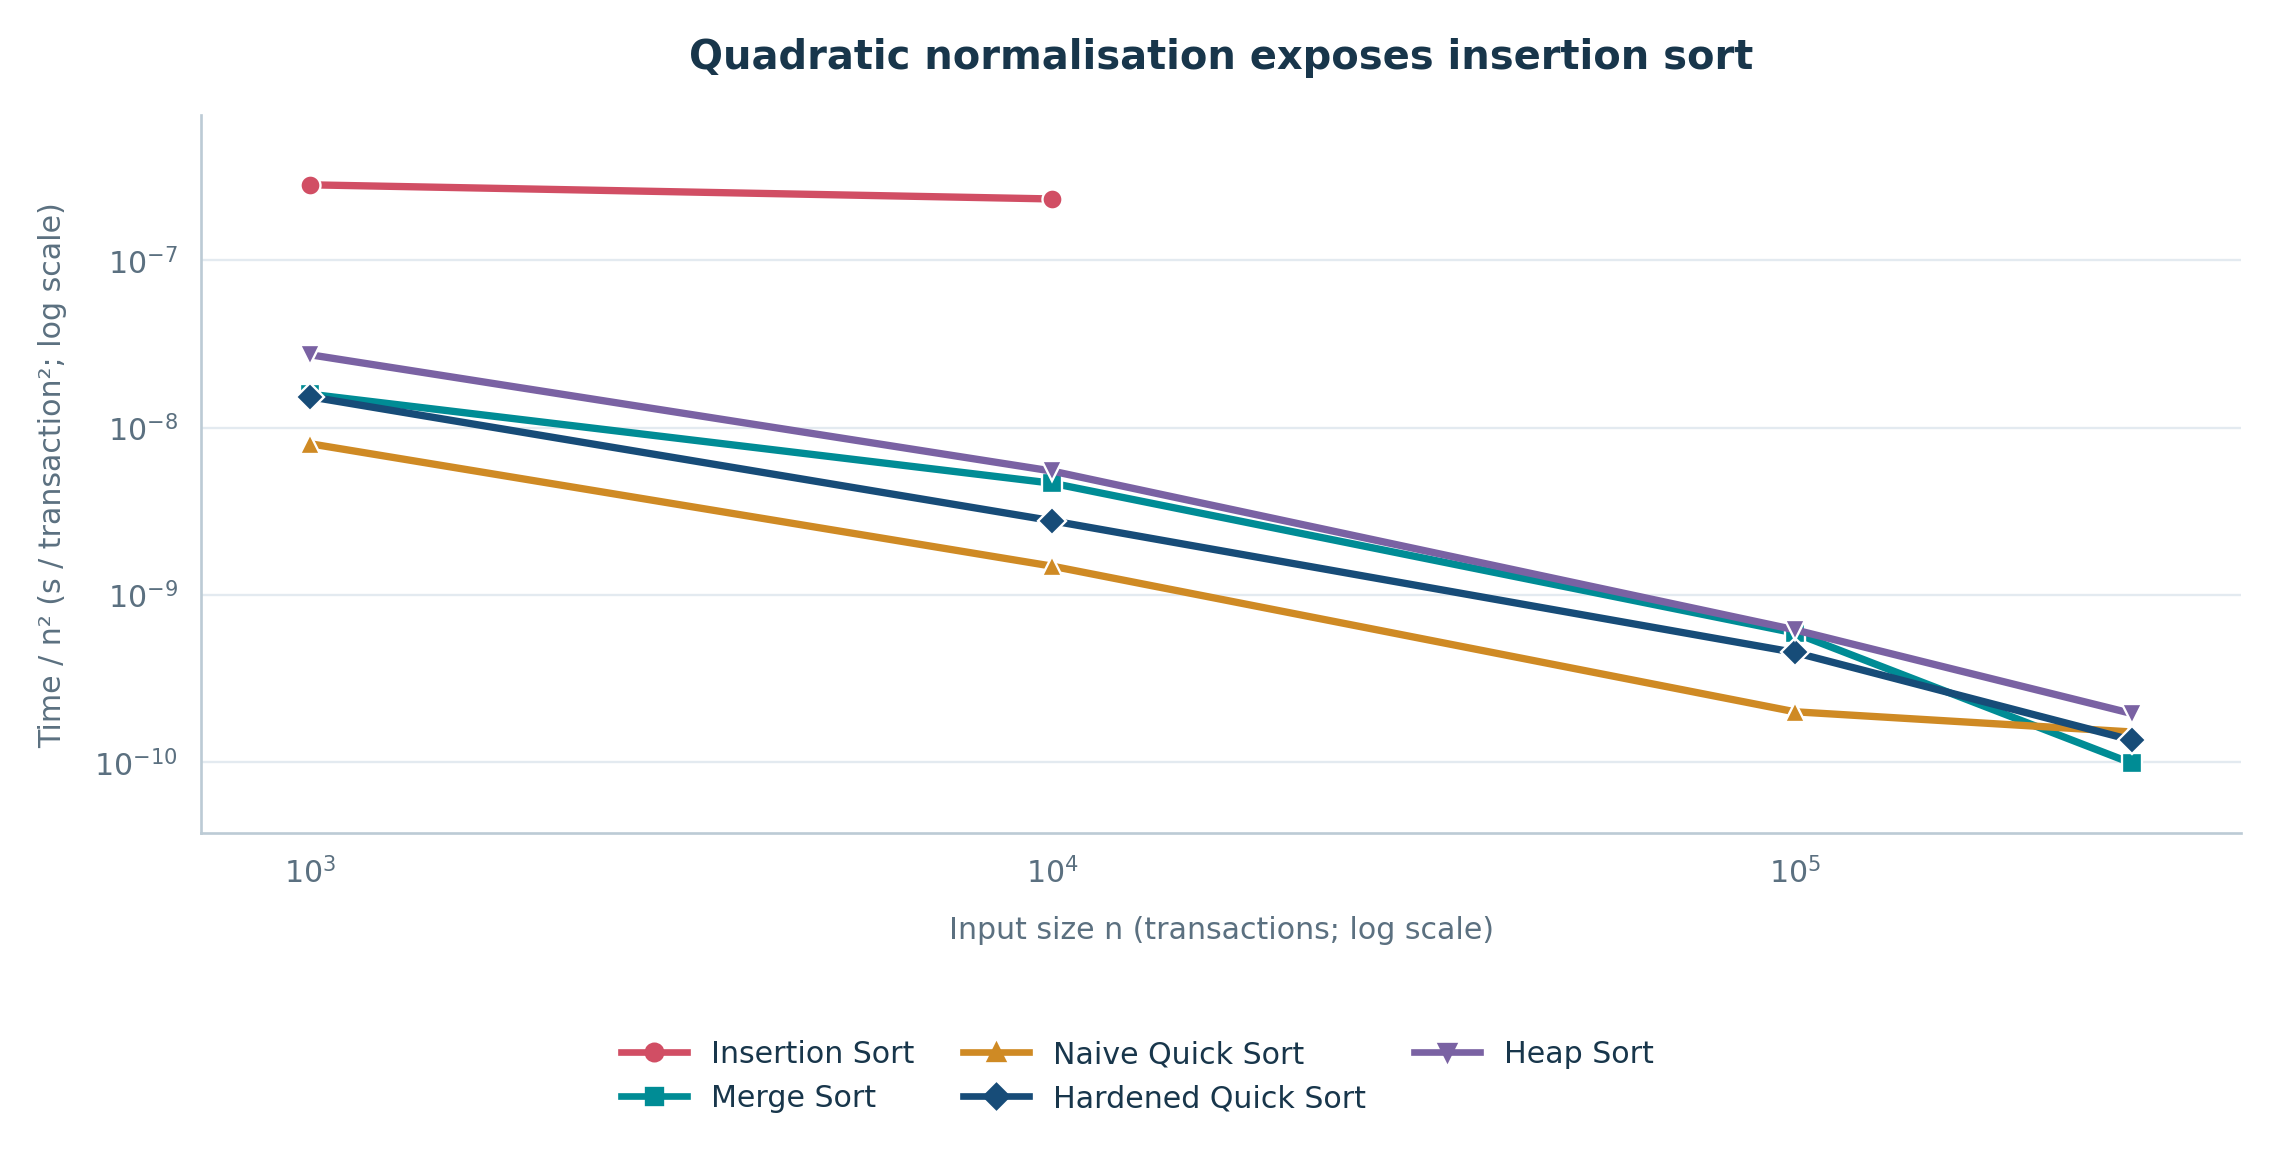

In [15]:
show_figure("06_time_n2_vs_n_C2.png")

In [16]:
tour = pd.read_csv(ROOT / "outputs" / "raw" / "tournament.csv")
med = tour[tour.record_type == "median"].copy()
for col in ("n", "median_s", "comparisons", "moves"):
    med[col] = pd.to_numeric(med[col], errors="coerce")

slice_10k = med[med.n == 10_000].pivot_table(
    index="algorithm", columns="condition", values="median_s", aggfunc="first"
)
style_table(slice_10k)

condition,C1,C2,C3,C4,C5,C6
algorithm,,,,,,
Hardened Quick Sort,0.3234,0.2774,0.9016,0.6770,0.6071,0.0269
Heap Sort,0.2960,0.5498,0.3390,0.3861,0.4691,0.1950
Insertion Sort,22.3608,23.3007,0.0077,48.9755,0.2288,17.0110
Merge Sort,0.2513,0.4654,0.2090,0.2059,0.3480,0.4033
Naive Quick Sort,0.2567,0.1485,50.5520,49.3747,1.7069,16.6667


In [17]:
dnf = tour[tour.record_type == "dnf"]
print(f"timed median cells: {len(med)}")
print(f"genuine DNF cells:  {len(dnf)}")
dnf[["algorithm", "condition", "n", "dnf_reason"]].sort_values(
    ["algorithm", "condition", "n"]
).reset_index(drop=True)

timed median cells: 105
genuine DNF cells:  15


,algorithm,condition,n,dnf_reason
0,Insertion Sort,C1,100000,exceeded 300s watchdog
1,Insertion Sort,C1,284807,exceeded 300s watchdog
2,Insertion Sort,C2,100000,exceeded 300s watchdog
3,Insertion Sort,C2,284807,exceeded 300s watchdog
4,Insertion Sort,C4,100000,exceeded 300s watchdog
5,Insertion Sort,C4,284807,exceeded 300s watchdog
6,Insertion Sort,C5,284807,historical completed run exceeded 300 s; recla...
7,Insertion Sort,C6,100000,exceeded 300s watchdog
8,Insertion Sort,C6,284807,exceeded 300s watchdog
9,Naive Quick Sort,C3,100000,exceeded 300s watchdog


## D. Top-K: full sort vs size-K heap vs bounded buffer

At $K=52$ the heap keeps only 52 candidates; the buffer maintains a sorted
52-record list and shifts on acceptance; the full sort orders all 10,000
records and takes a prefix.  All three must return the **same ordered queue**.

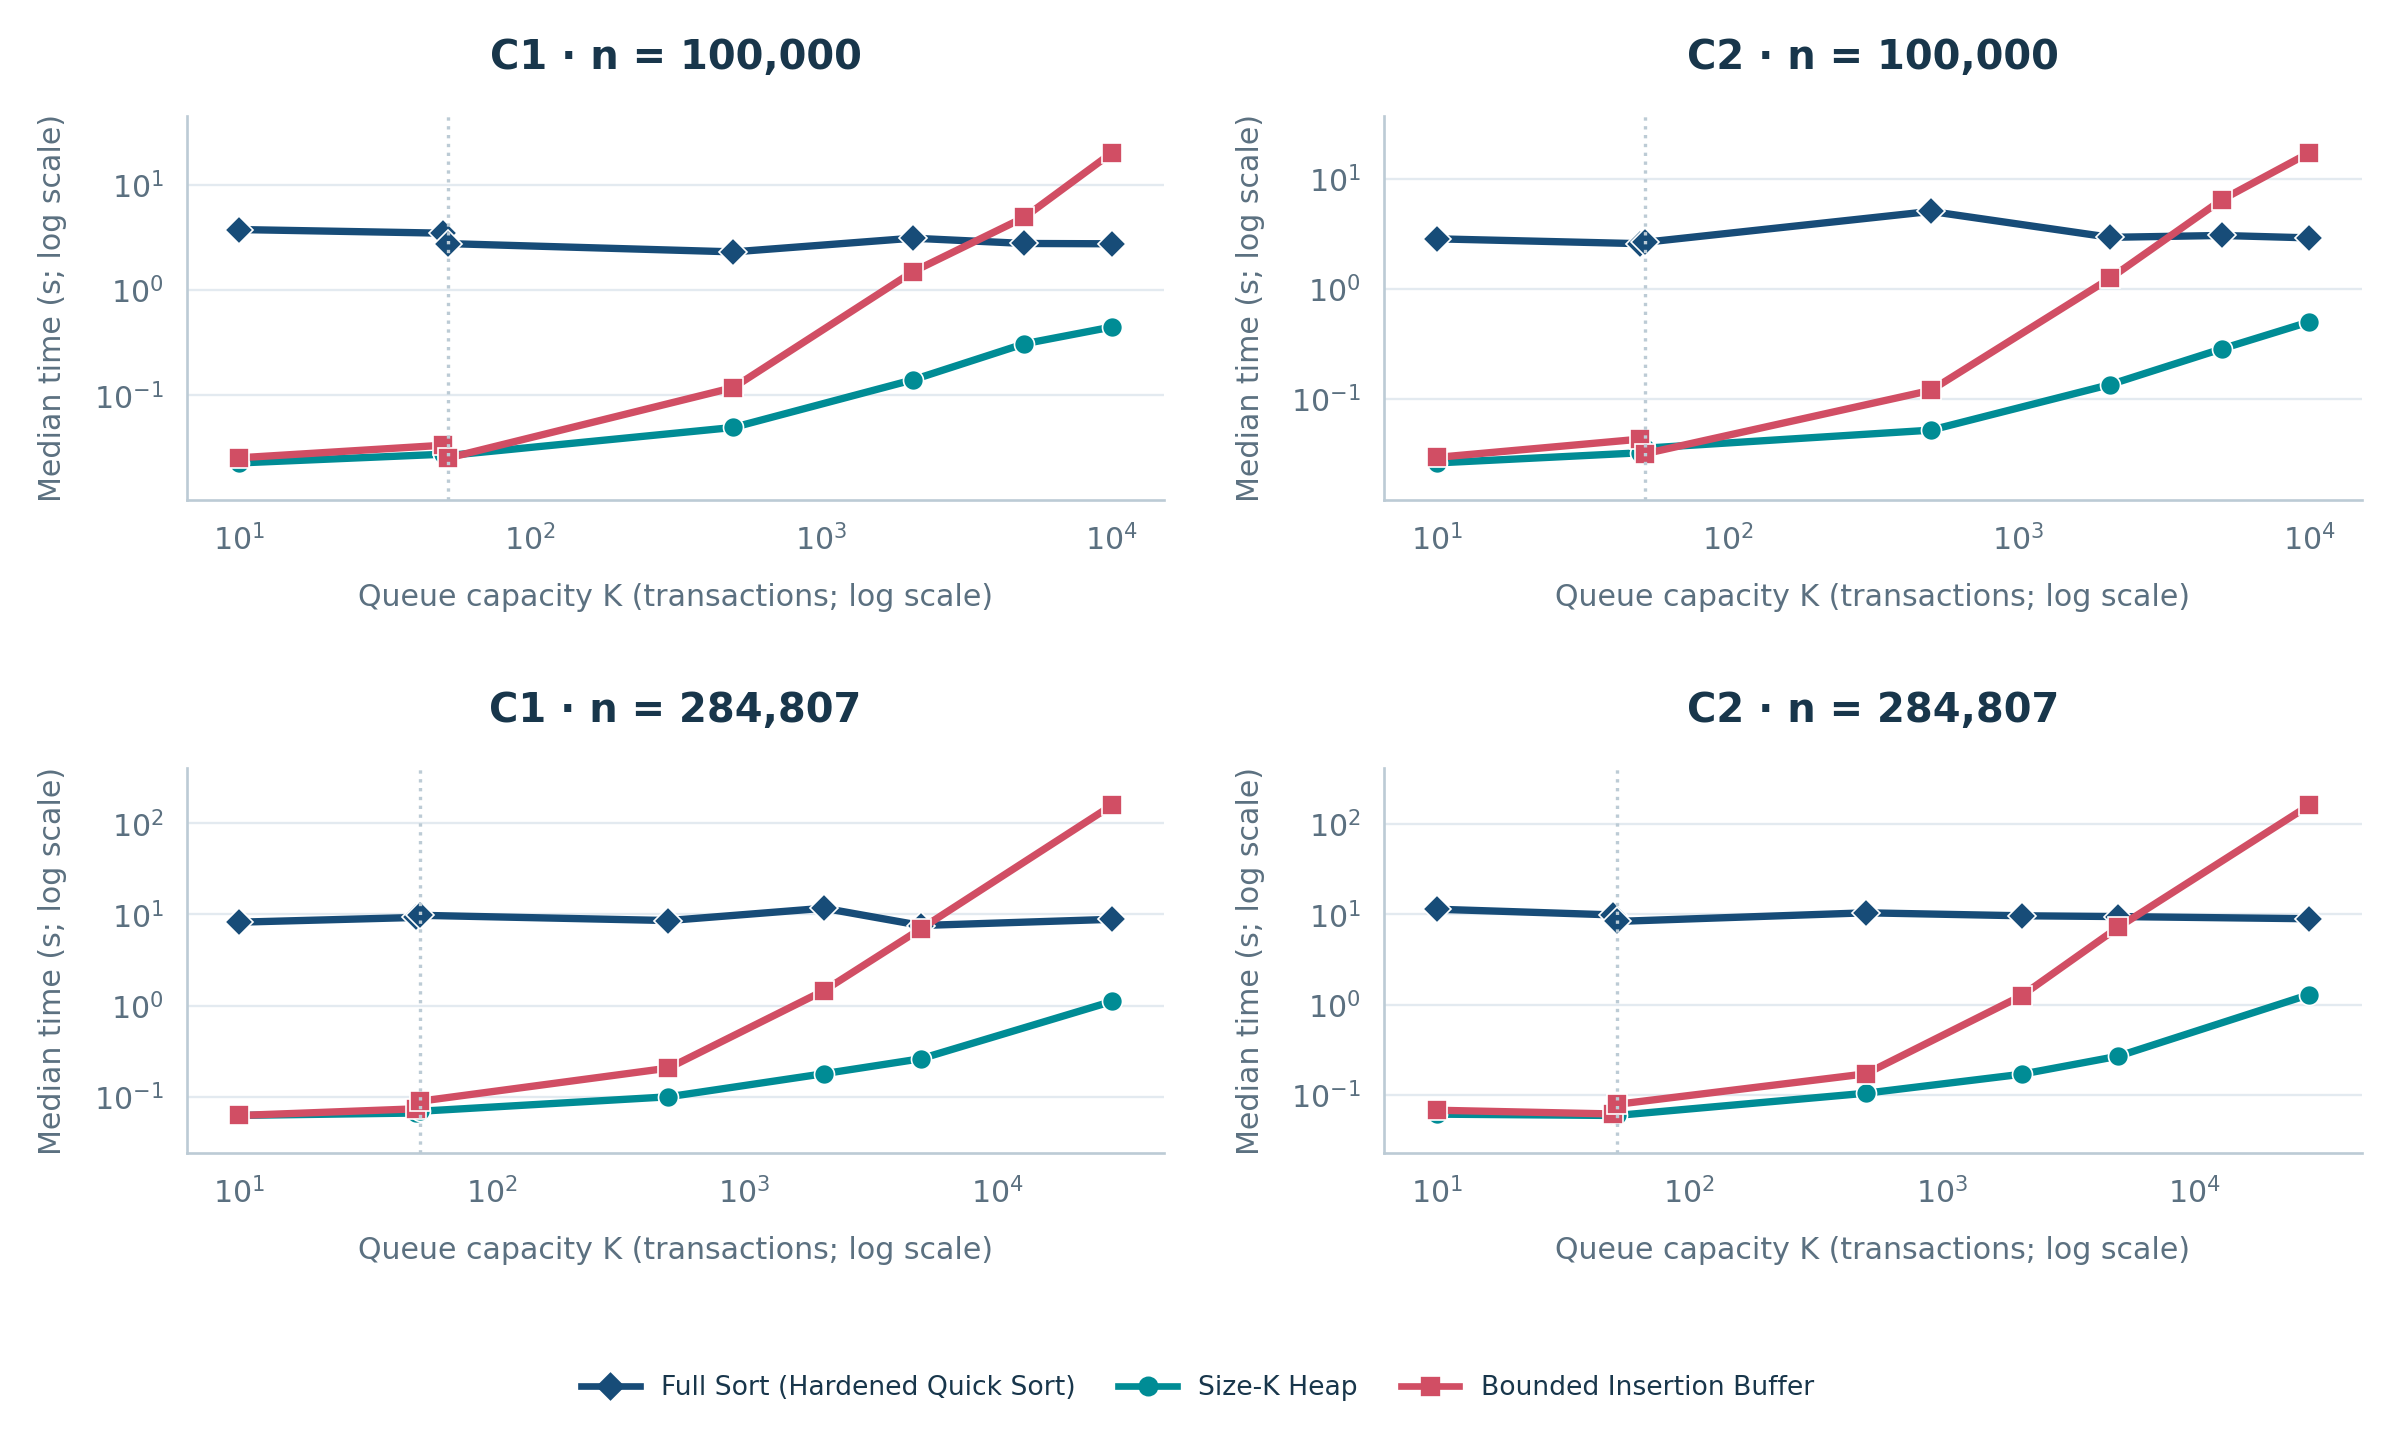

In [18]:
show_figure("09_topk_cost.png")

In [19]:
k = CONFIG.k
check = records[:10_000]

def timed(make_output):
    counters = Counters()
    order = TriageOrder("triage", counters)
    start = time.perf_counter()
    output = make_output(order, counters)
    return time.perf_counter() - start, output, counters

work_full = list(check)
def full_queue(order,counters):
    SORT_ALGORITHMS["Hardened Quick Sort"](work_full,order,counters)
    output=work_full[:k]
    counters.moves+=len(output)
    return output
t_full, q_full, c_full = timed(full_queue)
t_heap, q_heap, c_heap = timed(lambda order, counters: topk_heap(check, k, order, counters))
t_buf, q_buf, c_buf = timed(lambda order, counters: topk_buffer(check, k, order, counters))

assert q_full == q_heap == q_buf == sorted(check, key=triage_key)[:k]
print(f"all three queues identical: {len(q_heap)} records")
pd.DataFrame(
    [
        {"method": "hardened sort + prefix", "elapsed_s": round(t_full, 4),
         "comparisons": c_full.comparisons, "moves": c_full.moves},
        {"method": "size-K heap", "elapsed_s": round(t_heap, 4),
         "comparisons": c_heap.comparisons, "moves": c_heap.moves},
        {"method": "bounded buffer", "elapsed_s": round(t_buf, 4),
         "comparisons": c_buf.comparisons, "moves": c_buf.moves},
    ]
)

all three queues identical: 52 records


,method,elapsed_s,comparisons,moves
0,hardened sort + prefix,0.1041,152157,389071
1,size-K heap,0.0046,12904,4456
2,bounded buffer,0.0060,11827,8190


In [20]:
queue_preview = pd.DataFrame(
    [
        {"rank": i + 1, "txn_id": t.txn_id, "band": t.band,
         "Amount": round(t.amount, 2), "Time": t.time, "Class": t.label}
        for i, t in enumerate(q_heap[:10])
    ]
)
print(f"frauds in the whole 10,000 sample: {sum(t.label for t in check)}")
print(f"frauds in this K=52 queue: {sum(t.label for t in q_heap)}")
style_table(queue_preview)

frauds in the whole 10,000 sample: 20
frauds in this K=52 queue: 8


,rank,txn_id,band,Amount,Time,Class
0,1,227922,9,10000.0000,145283.0000,0
1,2,67725,9,5657.5400,52672.0000,0
2,3,117384,9,3759.3900,74657.0000,0
3,4,244699,9,1565.1200,152452.0000,0
4,5,78383,9,1502.3600,57502.0000,0
5,6,20261,9,870.0000,30907.0000,0
6,7,153852,9,779.8600,100384.0000,0
7,8,184330,9,570.0000,126199.0000,0
8,9,79297,9,390.6500,57957.0000,0
9,10,158023,9,360.0000,110803.0000,0


## Fraud capture versus $K$

The curve is computed once on the full file by `scripts/analyze_data.py` and
read here from `outputs/analysis/fraud_curve.csv`.  It uses `Class` only after
the queue is built.

In [21]:
curve = pd.read_csv(ROOT / "outputs" / "analysis" / "fraud_curve.csv")
required = [10, 50, 52, 500, 5000, 28480]
curve.set_index("k").loc[required].reset_index()

,k,frauds_captured,total_frauds,fraction
0,10,0,492,0.000000
1,50,0,492,0.000000
2,52,0,492,0.000000
3,500,63,492,0.128049
4,5000,361,492,0.733740
5,28480,438,492,0.890244


smallest K reaching 50% capture: 2,068 (246/492 frauds)
K=52 captures 0 frauds


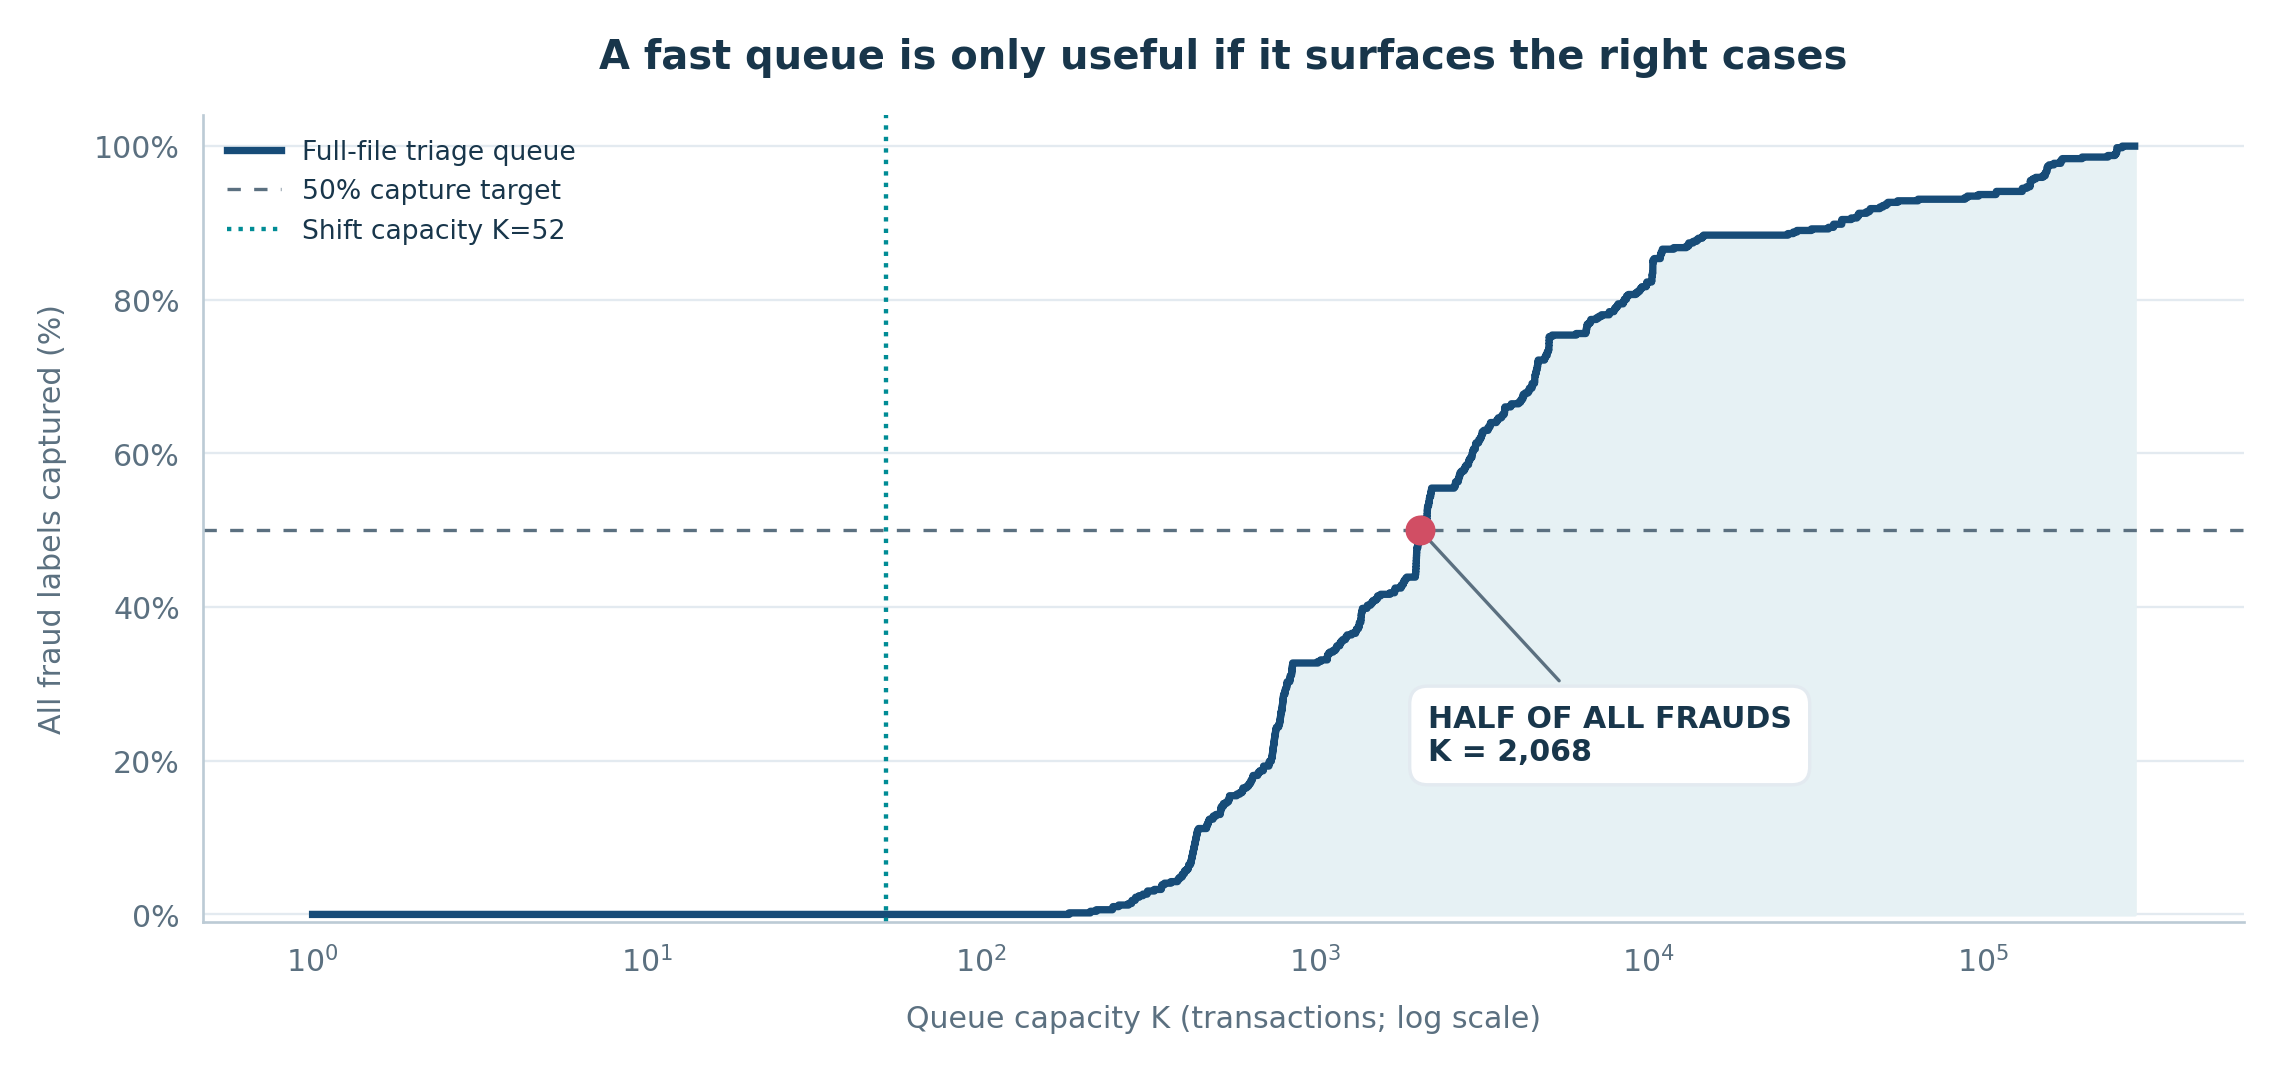

In [22]:
half = curve[curve.fraction >= 0.5].iloc[0]
print(f"smallest K reaching 50% capture: {int(half.k):,} "
      f"({int(half.frauds_captured)}/{int(half.total_frauds)} frauds)")
print(f"K=52 captures {int(curve.loc[curve.k == 52, 'frauds_captured'].iloc[0])} frauds")
show_figure("08_fraud_capture.png")

## E. Live feed

The full 48-hour file is split into consecutive `Time` windows.  After every
window the committed queue is the top 52 of all records seen so far.
**A** re-ranks the whole prefix; **B** offers each new record to a maintained
size-52 heap; **C** sorts the new window and merges it into the current queue.
The table below is read from the five-run summaries in `outputs/raw/livefeed.csv`.
A strategy that exceeded the 300 s watchdog has no summary row; the DNF table
below it makes that explicit rather than showing a missing number.

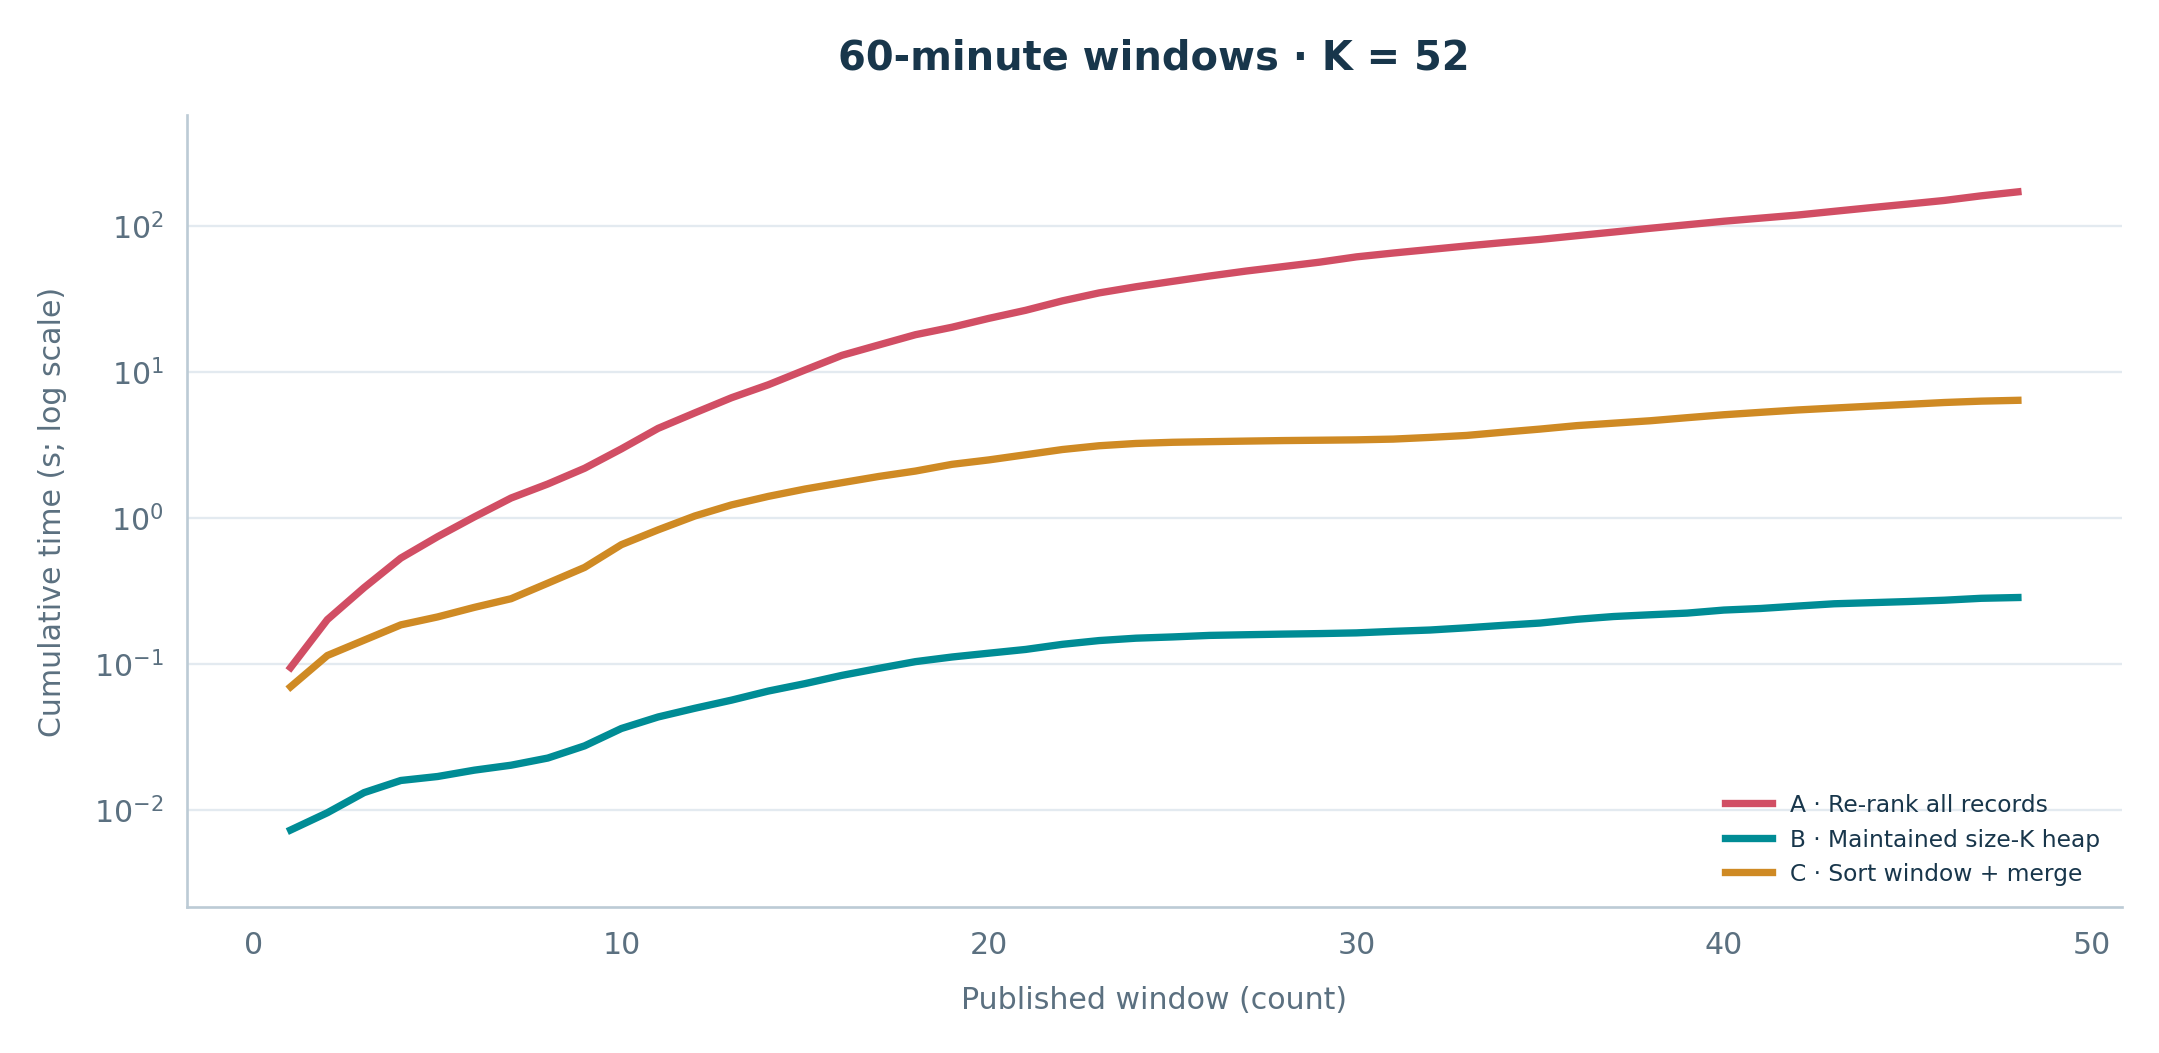

In [23]:
show_figure("10_livefeed_1h.png")

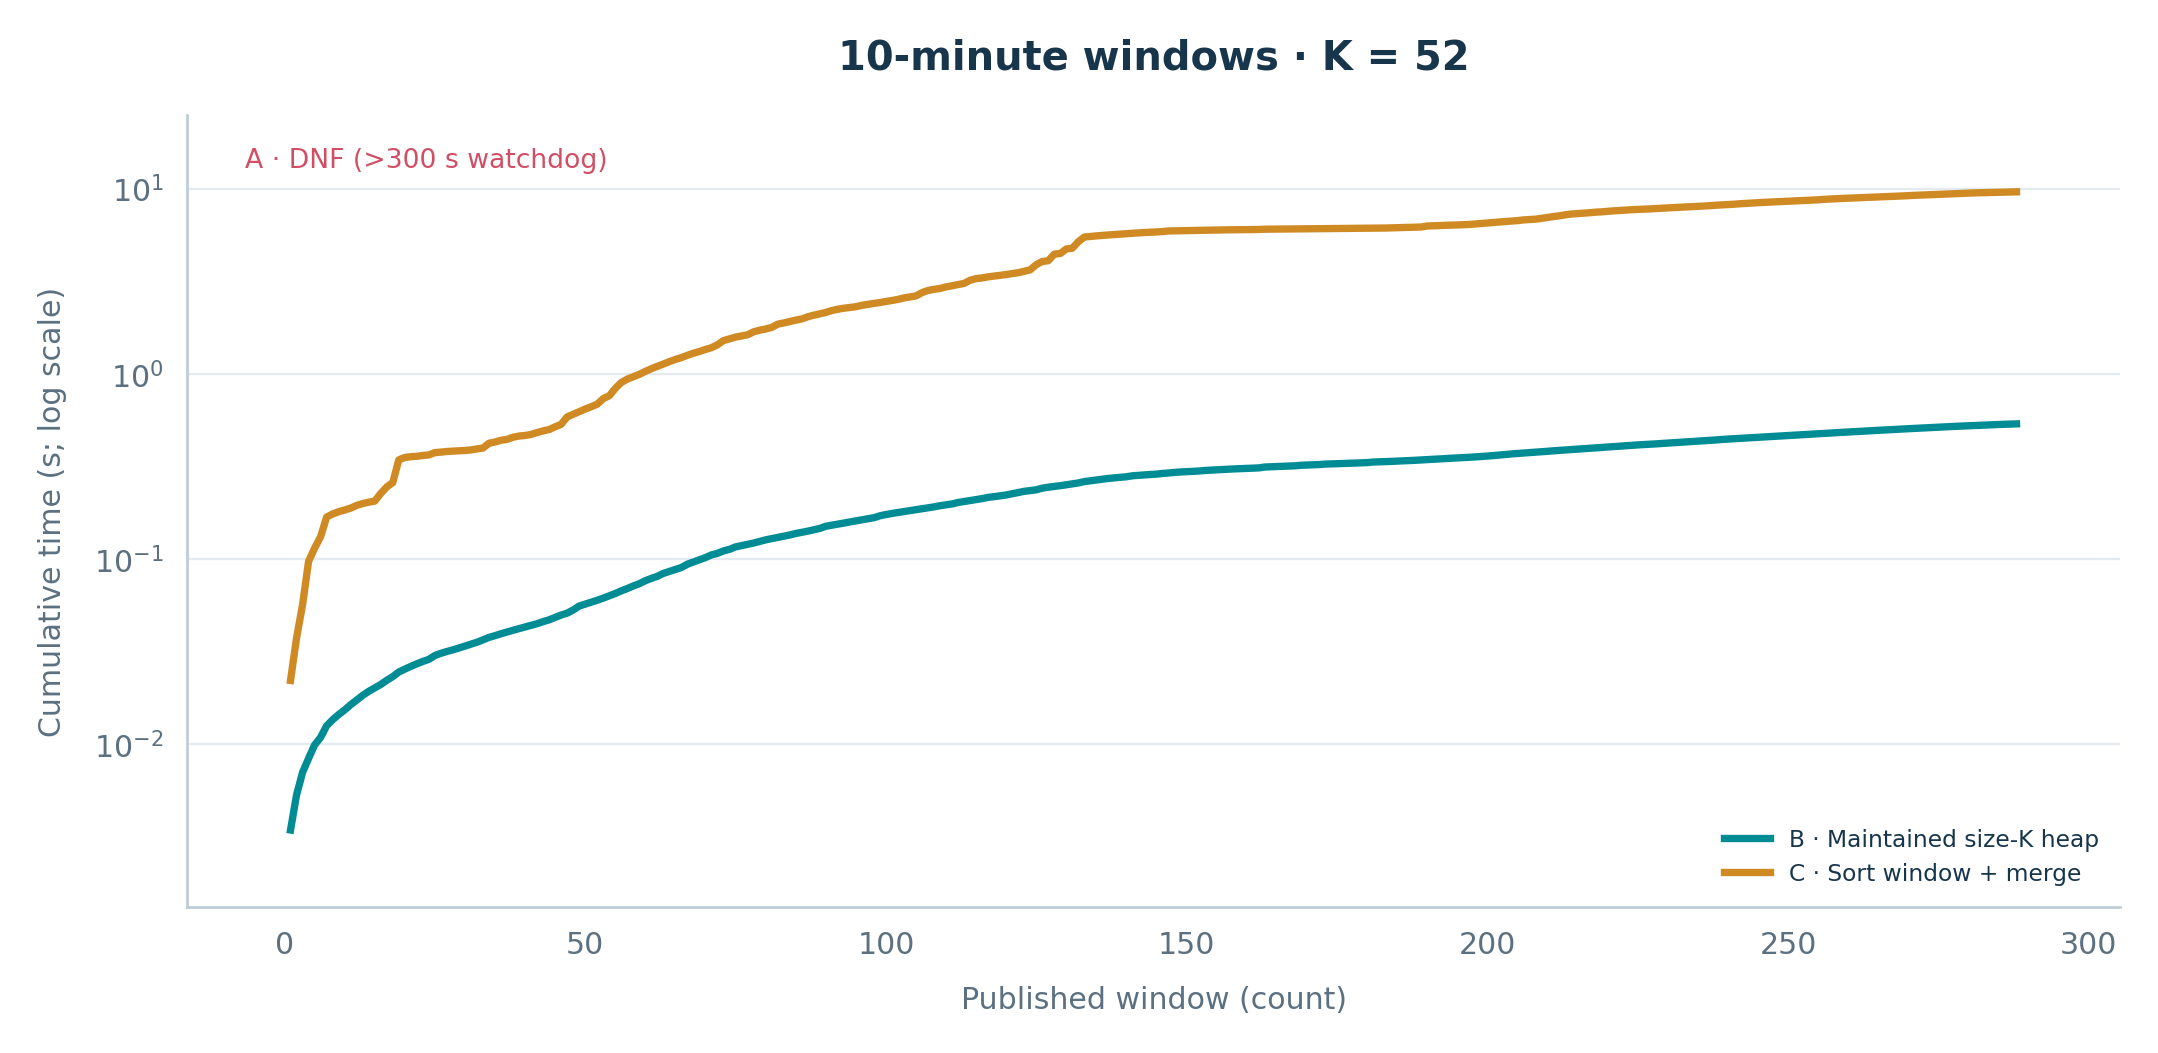

In [24]:
show_figure("11_livefeed_10min.png")

In [25]:
live_path = ROOT / "outputs" / "raw" / "livefeed.csv"
if live_path.exists():
    live = pd.read_csv(live_path)
    summaries = live[live.record_type == "summary"].copy()
    summaries["width"] = summaries["width_s"].map({3600: "1 hour", 600: "10 min"})
    display(
        summaries.pivot_table(
            index="width", columns="strategy", values="median_s", aggfunc="first"
        ).round(3)
    )
    dnf_live = live[(live.record_type == "dnf") & (live.experiment == "livefeed")]
    if len(dnf_live):
        display(dnf_live[["strategy", "width_s", "dnf_reason"]])
else:
    print("livefeed.csv is not present; run scripts/run_livefeed.py --memory")

strategy,heap,merge,rerank
width,,,
1 hour,0.284,6.364,170.586
10 min,0.538,9.615,NaN


,strategy,width_s,dnf_reason
2810,rerank,600,exceeded 300 s measured-simulation deadline


## F. The mathematical case: M6 on C6

C6 is the assignment's literal **band-only** comparator.  It has huge ties, so
exact sequence equality with a total-order reference is impossible without
adding an illegal secondary key.  A literal C6 result is validated as a
permutation with non-increasing bands and with no access to Amount, Time,
txn_id or Class.  This is the disclosed specification clash recorded in
`docs/specification_and_decisions.md`.

For Naive Quick Sort (last-pivot Lomuto), a one-band block of size $m$ costs
$m(m-1)/2$ comparisons.  Grouping the actual band sizes gives the prediction
below; the 10,000 exact-sequence simulation is shown for comparison.

In [26]:
analysis = json.loads(
    (ROOT / "outputs" / "analysis" / "data_analysis.json").read_text()
)
m6 = analysis["c6_band_analysis"]
rows = []
for n in ("1000", "10000", "100000", "284807"):
    item = m6[n]
    sub = med[(med.algorithm == "Naive Quick Sort") &
              (med.condition == "C6") & (med.n == int(n))]
    rows.append(
        {
            "n": int(n),
            "band sizes": ", ".join(str(v) for v in item["band_sizes"].values()),
            "group formula": item["predicted_comparisons_group_formula"],
            "exact element model": item["predicted_comparisons_exact_sequence"],
            "measured": int(sub.comparisons.iloc[0]) if len(sub) else "DNF",
        }
    )
style_table(pd.DataFrame(rows))

,n,band sizes,group formula,exact element model,measured
0,1000,"84, 371, 397, 107, 24, 8, 5, 4",156718,158620.0000,158620
1,10000,"719, 3809, 3964, 1094, 225, 98, 59, 32",15995154,16023019.0000,16023019
2,100000,"7399, 37639, 39769, 11246, 2152, 995, 488, 312",1592671008,—,DNF
3,284807,"21156, 107410, 113116, 32084, 6006, 2797, 1376, 862",12927671903,—,DNF


## H. Recommendation

The recommendation is derived from the measured tables above and
from `results.csv`; see Section H of the PDF for the full argument, including
the assumptions under which each recommendation would fail.

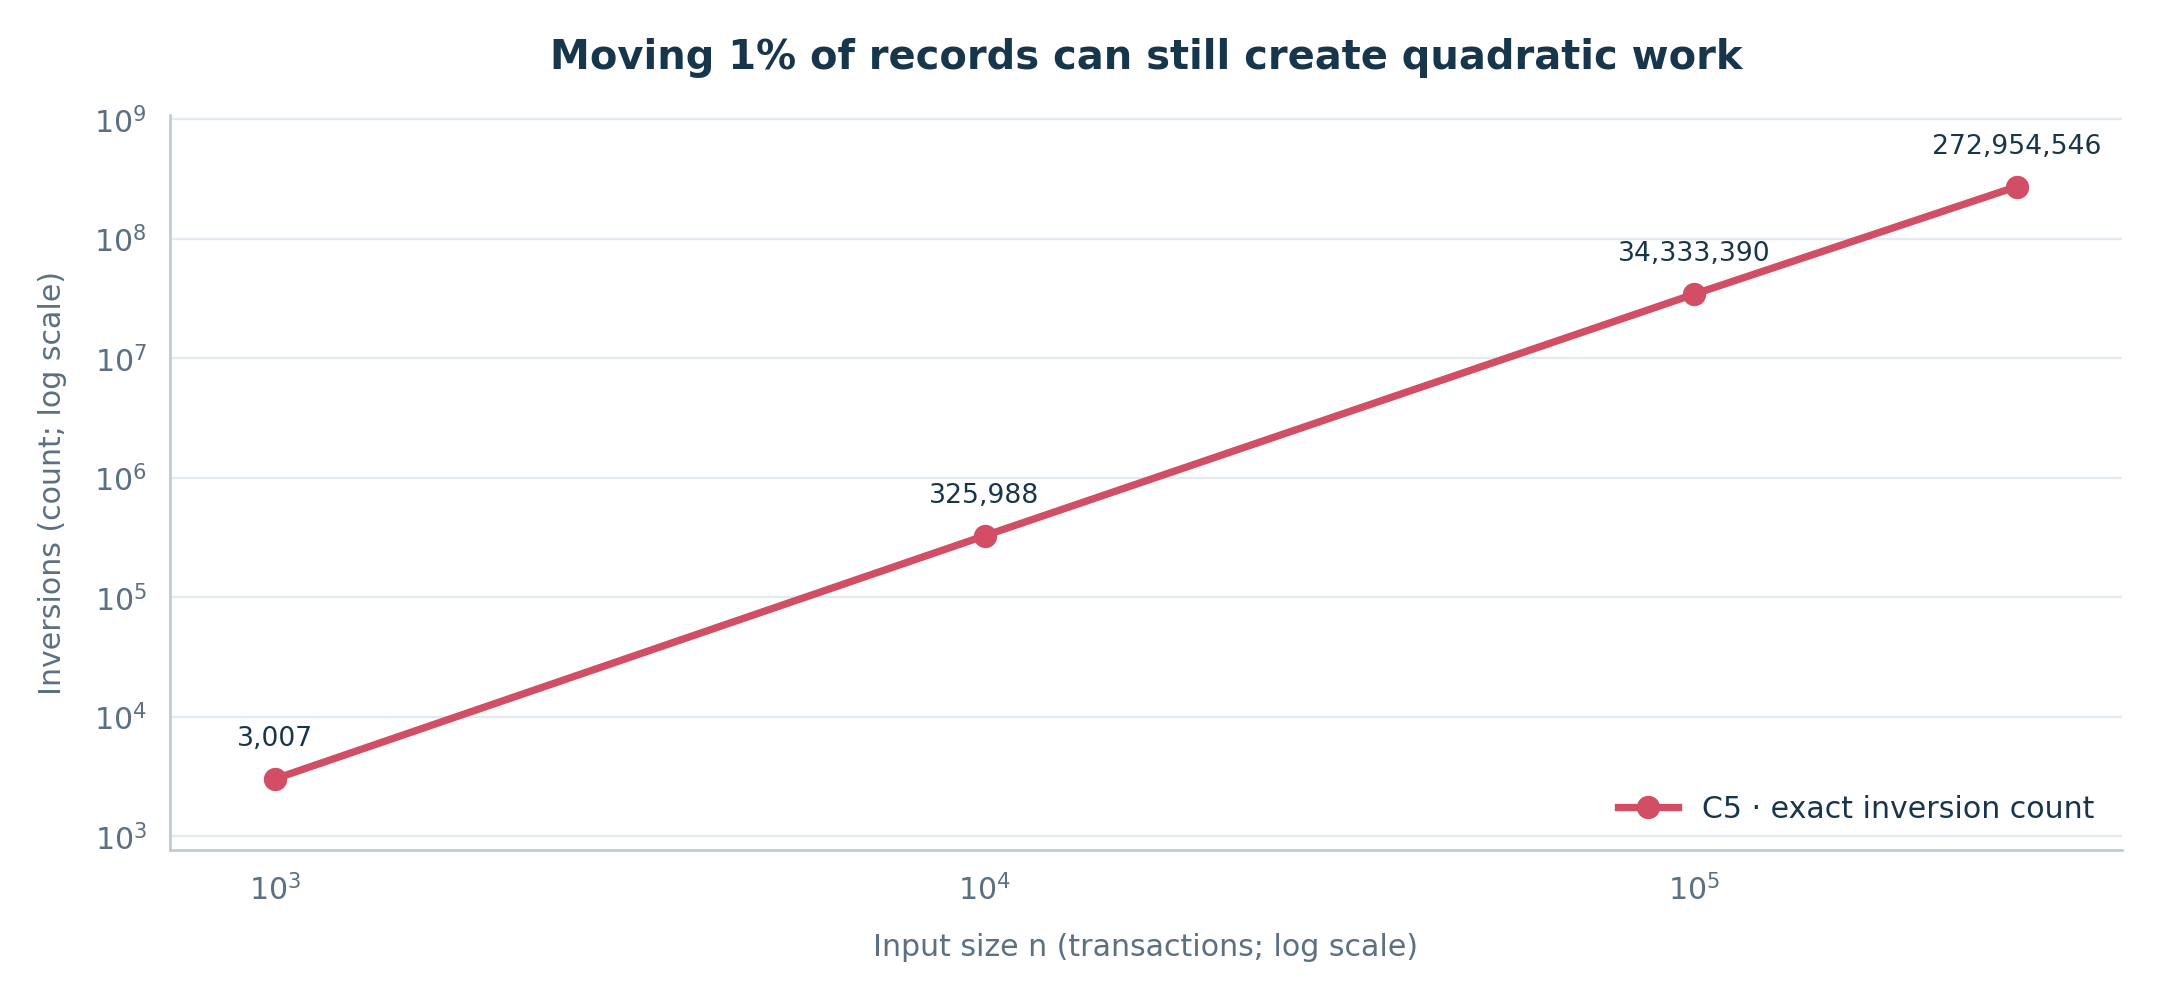

In [27]:
show_figure("12_c5_inversions.png")

In [28]:
report = ROOT / "23I-2581-A2-DS-B.pdf"
results = ROOT / "results.csv"
print(f"report exists: {report.exists()}  ({report})")
print(f"results.csv exists: {results.exists()}  ({results})")
if results.exists():
    res = pd.read_csv(results)
    print(f"results rows: {len(res):,}")
    display(res.head(3))

report exists: True  (C:\Users\hp\Desktop\University\3. Algo\2. Assignments\ASM - 2\midnight_queue\23I-2581-A2-DS-B.pdf)
results.csv exists: True  (C:\Users\hp\Desktop\University\3. Algo\2. Assignments\ASM - 2\midnight_queue\results.csv)
results rows: 4,876


,record_type,problem,experiment,prediction_id,algorithm,strategy,condition,n,k,width_s,...,dnf_reason,extrapolated,largest_completed_n,fraud_capture_count,fraud_fraction,queue_size,seen,window_records,cumulative_s,notes
0,console_run,Bonus,analyst_console,NaN,Merge Sort,NaN,C1,1000,52.0,NaN,...,NaN,NaN,NaN,NaN,NaN,52.0,NaN,NaN,NaN,single demo run; excluded from five-run median...
1,console_run,Bonus,analyst_console,NaN,Merge Sort,NaN,C1,1000,52.0,NaN,...,NaN,NaN,NaN,NaN,NaN,52.0,NaN,NaN,NaN,single demo run; excluded from five-run median...
2,console_run,Bonus,analyst_console,NaN,Naive Quick Sort,NaN,C1,1000,52.0,NaN,...,NaN,NaN,NaN,NaN,NaN,52.0,NaN,NaN,NaN,single demo run; excluded from five-run median...


## Reproduction

From the project root, with `$env:PYTHONPATH = "src"`:

```powershell
python scripts/prepare.py
python -m pytest -q
python scripts/run_dnf.py
python scripts/run_tournament_parallel.py --workers 4
python scripts/measure_memory.py
python scripts/run_topk.py --extra-k 2068
python scripts/measure_topk_memory.py
python scripts/run_livefeed.py --memory
python scripts/analyze_data.py
python -m midnight_queue.plotting
python scripts/assemble_results.py
python scripts/build_submission.py
```

The dataset is **not** included in the submission archive.  Place
`creditcard.csv` under `data/` before running the notebook or the harness.

## Editable report and figure exports

The editable report is **23I-2581-A2-DS-B.tex** in the project root.
Its relative image paths point to **report/images/**; each chart is available
as a vector PDF and a high-resolution PNG. The complete figure collection also
includes SVG exports in **outputs/figures/**.

Part G is reserved for the demo and omitted from the report as requested.
The assignment's C6 tie conflict and the interpretation used are documented in
**docs/specification_and_decisions.md**. No missing requirement or timeout is hidden.

## Bonus analyst console and live preparation

From the project root, run **python scripts/run_console.py** and open
**http://127.0.0.1:8765**. Choose any required full sort or Top-K selector,
set K, and inspect every queued record through pagination. The interface
shows actual runtime, comparisons and moves, and verifies its output.
Single demonstrations stay separate from the report's five-run medians.

The corrected **viva_prep.md** explains invariants, M1-M8, current measurements
and hands-on practice. **docs/demo_runbook.md** explains how to demonstrate
the console and measure the actual Part G request when it arrives.
Part G remains reserved for the demo; viva marks require your live explanation
and code modification. Bonus credit is conditional on completing A-H.